Cargamos la ROI generada en el Módulo 1 (en gris y en color). El video se usará posteriormente.

In [46]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from skimage.feature import graycomatrix, graycoprops

VIDEO_PATH = "../data/raw/Registro A_2.MOV"
ROI_PATH = "../data/reference/roi_A_gray.png"
ROI_RGB_PATH = "../data/reference/roi_A_rgb.png"

# cargar la ROI en escala de grises y en color
roi_gray = cv2.imread(ROI_PATH, cv2.IMREAD_GRAYSCALE)
roi_bgr = cv2.imread(ROI_RGB_PATH)

if roi_gray is None:
    raise RuntimeError(f"No se pudo cargar la ROI: {ROI_PATH}")
if roi_bgr is None:
    raise RuntimeError(f"No se pudo cargar la ROI: {ROI_RGB_PATH}")

roi_rgb = cv2.cvtColor(roi_bgr, cv2.COLOR_BGR2RGB)

print("ROI gris:", roi_gray.shape)
print("ROI RGB:", roi_rgb.shape)

ROI gris: (130, 320)
ROI RGB: (130, 320, 3)


Se utilizará la ROI cuantizada a 32 niveles (5 bits por canal). Esto será útil para que la GLCM sea mucho más chica y que sus estadísticas sean más estables con pocos píxeles.

In [47]:
NIVELES = 32                    # niveles de intensidad
paso = 256 // NIVELES          

# Cuantización, reducir las intensidades de 0-255 a 0-31
roi_cuant = (roi_rgb // paso).astype(np.uint8)
gray_cuant = (roi_gray // paso).astype(np.uint8)

Usamos la segmentación por Watershed del módulo 2, ya que fue la que mejor delimitó la pupila. Además, sumamos un cierre morfológico, que según la última tabla del mismo módulo fue de las operaciones que menos modificó la máscara.

A partir de la máscara extraemos el contorno externo de la pupila. Hacemos una función con la segmentación para poder reutilizarla en el procesamiento de cada frame del video.

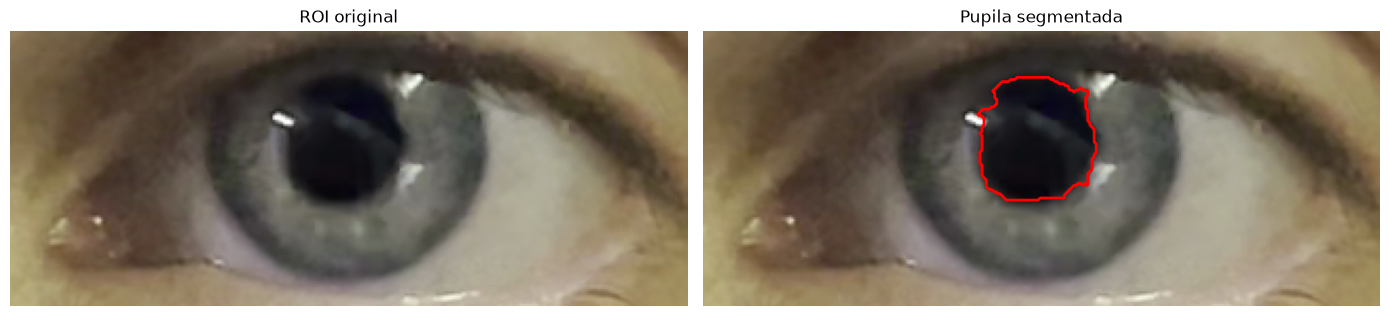

In [48]:
# centro inicial aproximado de la pupila
center_x, center_y = 155, 50

def segmentar_pupila(gris, cx=center_x, cy=center_y, radio=20):
    """Segmenta la pupila con Watershed y devuelve su máscara y contorno"""
    # Hago el contraste + suavizado, tal como se hizo en el módulo 2
    contraste = np.clip(gris.astype(np.float32) * 1.5, 0, 255).astype(np.uint8)
    suavizada = cv2.GaussianBlur(contraste, (5, 5), 0)

    # Marcadores: 1 = pupila segura, 2 = fondo seguro (fuera de la elipse)
    marcadores = np.zeros(gris.shape, dtype=np.int32)
    cv2.circle(marcadores, (int(cx), int(cy)), radio, 1, -1)
    zona = np.zeros(gris.shape, dtype=np.uint8)
    cv2.ellipse(zona, (int(cx), int(cy)), (60, 55), 0, 0, 360, 1, -1)
    marcadores[zona == 0] = 2

    # Watershed para separar la pupila del entorno
    ws = cv2.watershed(cv2.cvtColor(suavizada, cv2.COLOR_GRAY2BGR), marcadores)
    mascara = (ws == 1).astype(np.uint8) * 255

    # Cierre morfológico con kernel elíptico de 5x5
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    mascara = cv2.morphologyEx(mascara, cv2.MORPH_CLOSE, kernel)

    # Contorno externo de la máscara
    contornos, _ = cv2.findContours(mascara.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    contorno = max(contornos, key=cv2.contourArea) if contornos else None
    return mascara, contorno

mask_pupila, contorno = segmentar_pupila(roi_gray)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.imshow(roi_rgb)
plt.title("ROI original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(roi_rgb)
plt.contour(mask_pupila > 0, colors="r", linewidths=2)
plt.title("Pupila segmentada")
plt.axis("off")

plt.tight_layout()
plt.show()

A continuación se calculará, a partir del contorno de la pupila, el área, perímetro, centroide, circularidad, excentricidad y ejes de la elipse ajustada

In [49]:
def descriptores_morfometricos(contorno):
    """Área, perímetro, centroide, circularidad y excentricidad del contorno."""
    area = cv2.contourArea(contorno)
    perimetro = cv2.arcLength(contorno, True)

    # Centroide a partir de los momentos del contorno
    m = cv2.moments(contorno)
    xc = m["m10"] / m["m00"]
    yc = m["m01"] / m["m00"]

    # Elipse que mejor se ajuste al contorno para obtener sus ejes
    elipse = cv2.fitEllipse(contorno)
    (_, _), (d1, d2), angulo = elipse
    eje_mayor, eje_menor = max(d1, d2), min(d1, d2)

    circularidad = 4 * np.pi * area / perimetro**2
    excentricidad = np.sqrt(1 - (eje_menor / eje_mayor) ** 2)

    return {
        "Área (px²)": area,
        "Perímetro (px)": perimetro,
        "Centroide X_c (px)": xc,
        "Centroide Y_c (px)": yc,
        "Circularidad": circularidad,
        "Excentricidad": excentricidad,
        "Eje mayor (px)": eje_mayor,
        "Eje menor (px)": eje_menor,
    }, elipse


desc, elipse = descriptores_morfometricos(contorno)

tabla_morfo = pd.DataFrame(desc, index=["Pupila (frame de referencia)"]).T
display(tabla_morfo.round(4))

,Pupila (frame de referencia)
Área (px²),2543.5000
Perímetro (px),210.6102
Centroide X_c (px),157.2433
Centroide Y_c (px),51.0816
Circularidad,0.7206
Excentricidad,0.3987
Eje mayor (px),60.1142
Eje menor (px),55.1307


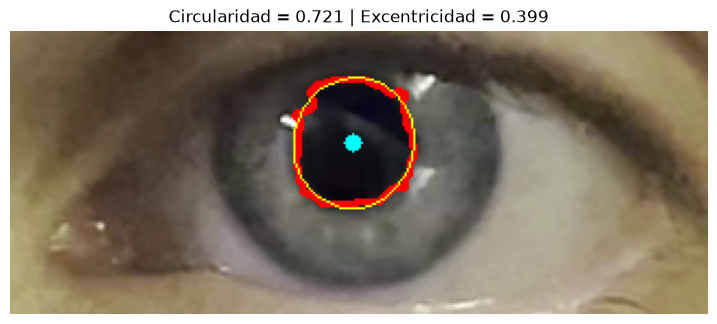

In [50]:
# Visualización: contorno, centroide y elipse ajustada
img = roi_rgb.copy()
cv2.drawContours(img, [contorno], -1, (255, 0, 0), 2)
cv2.ellipse(img, elipse, (255, 255, 0), 1)
cv2.circle(img, (int(round(desc["Centroide X_c (px)"])), int(round(desc["Centroide Y_c (px)"]))), 4, (0, 255, 255), -1)

plt.figure(figsize=(9, 5))
plt.imshow(img)
plt.title(f"Circularidad = {desc['Circularidad']:.3f} | Excentricidad = {desc['Excentricidad']:.3f}")
plt.axis("off")
plt.show()

Observando los resultados, se observa que el centroide de la pupila segmentada está en (157.2, 51.1), mientras que el centro asignado para aplicar Watershed se colocó en (155, 50), por lo que hay solo una leve diferencia entre estos dos centros.

La circularidad obtenida no es tan cercana a 1 por los bordes irregulares de la segmentación, que igualmente es adecuada para el análisis ya que, como se observa, rodea correctamente la pupila.

Más alla de que la circularidad no fue tan cercana a 1, el tamaño de los ejes de la elipse ajustada indican que la pupila sigue una forma aproximadamente circular.

A continuación, se calculará la media, desvío estándar, entropía y asimetría sobre la ROI de la pupila y el iris en los 3 canales de colores (RGB) de forma independiente.

Para obtener una máscara aproximada del iris en el frame de referencia, se aplica Watershed utilizando tres marcadores: iris seguro (un anillo alrededor de la pupila), pupila segura y fondo seguro (todo lo que queda fuera de una elipse grande). 

La máscara obtenida se utilizará para calcular las estadísticas de intensidad y textura, y su delimitación se verificará visualmente.

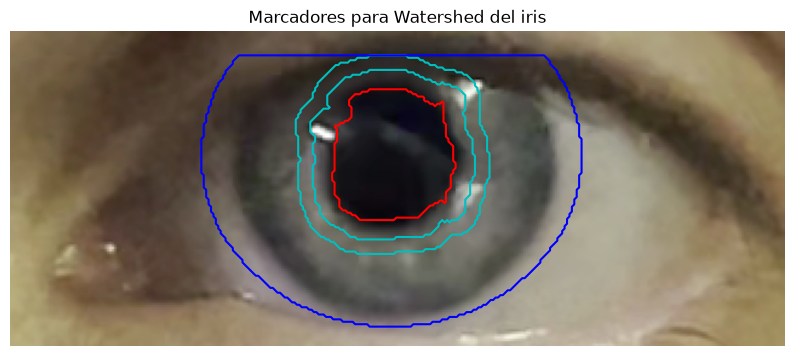

In [51]:
# Parámetros de los marcadores, en píxeles
ANILLO_INT, ANILLO_EXT = 6, 12   # radios que delimitan el anillo del iris "seguro"
FONDO_RX, FONDO_RY = 78, 70      # semiejes de la elipse que delimita el fondo seguro
Y_PARPADO = 10                   # franja superior que se considera fondo seguro

cx, cy = int(round(desc["Centroide X_c (px)"])), int(round(desc["Centroide Y_c (px)"]))

def kernel_elipse(r):
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * r + 1, 2 * r + 1))

marcadores_iris = np.zeros(roi_gray.shape, dtype=np.int32)

# 2 = fondo seguro: fuera de la elipse y en la franja superior
zona = np.zeros(roi_gray.shape, dtype=np.uint8)
cv2.ellipse(zona, (cx, cy), (FONDO_RX, FONDO_RY), 0, 0, 360, 1, -1)
marcadores_iris[zona == 0] = 2
marcadores_iris[:Y_PARPADO, :] = 2

# 1 = iris seguro: anillo cercano a la pupila
anillo_semilla = cv2.subtract(cv2.dilate(mask_pupila, kernel_elipse(ANILLO_EXT)),
                              cv2.dilate(mask_pupila, kernel_elipse(ANILLO_INT)))
marcadores_iris[anillo_semilla > 0] = 1

# 3 = pupila segura (para que el iris no la invada)
marcadores_iris[cv2.erode(mask_pupila, kernel_elipse(2)) > 0] = 3

plt.figure(figsize=(10, 5))
plt.imshow(roi_rgb)
plt.contour(marcadores_iris == 1, colors="c", linewidths=1.5)
plt.contour(marcadores_iris == 2, colors="b", linewidths=1.5)
plt.contour(marcadores_iris == 3, colors="r", linewidths=1.5)
plt.title("Marcadores para Watershed del iris")
plt.axis("off")
plt.show()

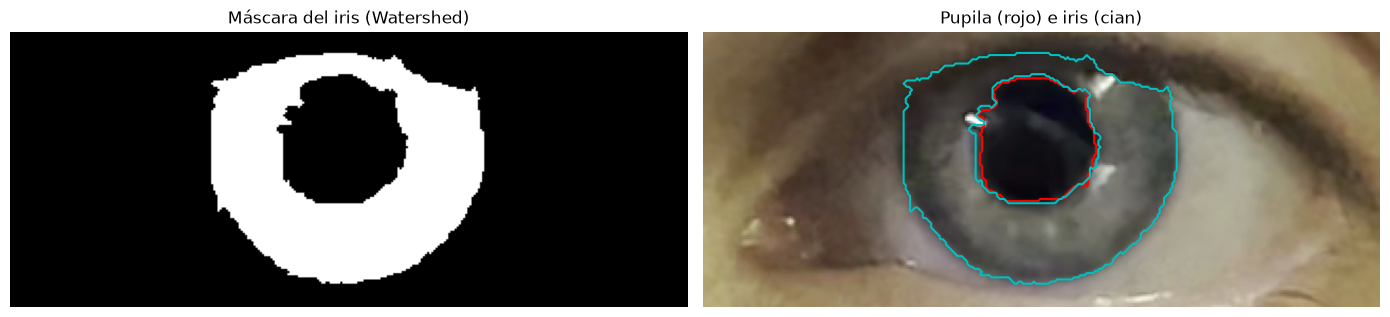

Píxeles de la pupila: 2638
Píxeles del iris:     8393


In [52]:
# Suavizar la imagen antes de aplicar Watershed
roi_suavizada_iris = cv2.GaussianBlur(roi_gray, (5, 5), 0)

# Los marcadores se copian para conservar la matriz original
ws_iris = cv2.watershed(cv2.cvtColor(roi_suavizada_iris, cv2.COLOR_GRAY2BGR), marcadores_iris.copy())

#Conservar únicamente la región etiquetada como iris
mask_iris = (ws_iris == 1).astype(np.uint8) * 255

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.imshow(mask_iris, cmap="gray")
plt.title("Máscara del iris (Watershed)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(roi_rgb)
plt.contour(mask_pupila > 0, colors="r", linewidths=1.5)
plt.contour(mask_iris > 0, colors="c", linewidths=1.5)
plt.title("Pupila (rojo) e iris (cian)")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Píxeles de la pupila:", cv2.countNonZero(mask_pupila))
print("Píxeles del iris:    ", cv2.countNonZero(mask_iris))

Los reflejos brillantes que se observan en el iris pueden causar errores en los cálculos estadísticos. Para reducir su influencia, se identifican los píxeles más claros mediante un umbral de intensidad y se amplia levemente la región detectada para excluir también los píxeles cercanos. Los píxeles detectados se eliminan de la máscara del iris antes de hacer los cálculos estadísticos.

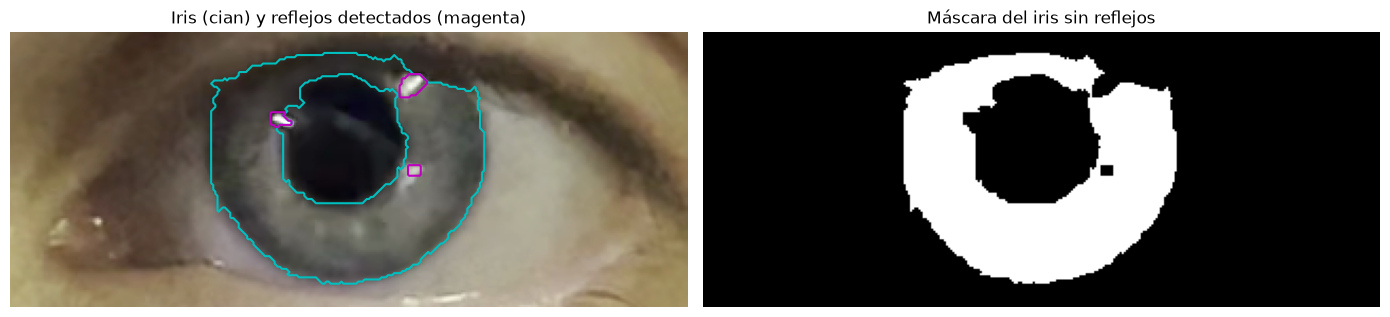

Píxeles del iris antes:   8393
Píxeles del iris después: 8209


In [55]:
UMBRAL_BRILLO = 205   # nivel de gris a partir del cual un píxel se considera reflejo

# Detectar píxeles muy brillantes y ampliar ligeramente las regiones detectadas
_, mask_brillo = cv2.threshold(roi_gray, UMBRAL_BRILLO, 255, cv2.THRESH_BINARY)
kernel_brillo = np.ones((5, 5), np.uint8)
mask_brillo = cv2.dilate(mask_brillo, kernel_brillo)

#Reflejos detectados dentro del iris
mask_reflejos_iris = cv2.bitwise_and(mask_iris, mask_brillo)

# Eliminar los reflejos de la máscara del iris 
mask_iris_sin_brillo = cv2.bitwise_and(mask_iris, cv2.bitwise_not(mask_brillo))

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.imshow(roi_rgb)
plt.contour(mask_iris > 0, colors="c", linewidths=1.5)
plt.contour(mask_reflejos_iris > 0, colors="m", linewidths=1.5)
plt.title("Iris (cian) y reflejos detectados (magenta)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask_iris_sin_brillo, cmap="gray")
plt.title("Máscara del iris sin reflejos")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Píxeles del iris antes:  ", cv2.countNonZero(mask_iris))
print("Píxeles del iris después:", cv2.countNonZero(mask_iris_sin_brillo))

La entropía mide la proporción de píxeles de la región en cada nivel de gris, mientras que la asimetría es positiva si la distribución tiene una cola hacia valores altos y negativa si la tiene hacia valores bajos.

In [78]:
def estadisticas_primer_orden(img_cuant, mascara, niveles=NIVELES):
    """Media, desvío, entropía y asimetría de cada canal (R, G, B), solo dentro de la máscara."""
    medias, desvios = cv2.meanStdDev(img_cuant, mask=mascara)

    filas = {}
    for i, canal in enumerate("RGB"):
        # Entropía (en bits) a partir del histograma de los niveles cuantizados
        hist = cv2.calcHist([img_cuant], [i], mascara, [niveles], [0, niveles]).ravel()
        p = hist / hist.sum()
        p = p[p > 0]
        entropia = -np.sum(p * np.log2(p))

        # Asimetría (skewness) de los valores de los píxeles dentro de la máscara
        valores = img_cuant[:, :, i][mascara > 0]
        asimetria = pd.Series(valores).skew()

        filas[canal] = {
            "Media": medias[i, 0],
            "Desvío": desvios[i, 0],
            "Entropía (bits)": entropia,
            "Asimetría": asimetria,
        }
    return pd.DataFrame(filas).T


stats_pupila = estadisticas_primer_orden(roi_cuant, mask_pupila)
stats_iris = estadisticas_primer_orden(roi_cuant, mask_iris_sin_brillo)

print("PUPILA")
display(stats_pupila.round(3))
print("IRIS")
display(stats_iris.round(3))

PUPILA


,Media,Desvío,Entropía (bits),Asimetría
R,2.528,1.740,2.430,2.687
G,2.466,1.808,2.526,2.314
B,3.162,1.593,2.348,2.689


IRIS


,Media,Desvío,Entropía (bits),Asimetría
R,10.065,3.129,3.567,0.088
G,9.877,3.280,3.608,-0.037
B,9.197,3.104,3.568,-0.017


La pupila tiene intensidades medias menores que el iris (es más oscura), junto con un desvío y entropía también menores (sus intensidades se concentran en una menor variedad de niveles cuantizados).

La asimetría de la pupila es positiva y alta, lo que indica una distribución con una cola hacia las intensidades más altas. Esto podría estar relacionado con el flash, que puede no haberse podido excluir de esta región.

Entre los canales RGB, las diferencias son pequeñas. En el iris, el canal B presenta una media levemente menor que los otros dos canales, mientras que las entropías son muy similares.

La GLCM describe la frecuencia con la que aparecen pares de intensidades cuantizadas a una distancia y dirección determinadas. Se calcula por separado para cada canal RGB, con una distancia de 1 píxel y cuatro direcciones:  0°, 45°, 90°, 180°.

A partir de las matrices se calculan el contraste, la homogeneidad, la energía y la correlación. Para obtener un valor por canal, estos parámetros se promedian sobre las cuatro direcciones.

In [56]:
DISTANCIAS = [1]
ANGULOS = [0, np.pi/4, np.pi/2, 3*np.pi/4]

def glcm_mascara(canal, mascara, niveles=NIVELES):
    # Reservar un nivel adicional para identificar el exterior de la máscara
    img = canal.copy()
    img[mascara == 0] = niveles
    glcm = graycomatrix(img, distances=DISTANCIAS, angles=ANGULOS,
                        levels=niveles + 1, symmetric=True, normed=False)
    
    # Eliminar el nivel adicional: quedan las GLCM dentro de la región
    glcm = glcm[:niveles, :niveles].astype(float)

    # Normalizar las matrices para trabajar con frecuencias relativas
    glcm /= glcm.sum(axis=(0, 1), keepdims=True)
    return glcm

def atributos_glcm(glcm):
    props = {"Contraste": "contrast", "Homogeneidad": "homogeneity",
             "Energía": "energy", "Correlación": "correlation"}
    return {nombre: graycoprops(glcm, p).mean() for nombre, p in props.items()}

In [57]:
# Calcular las GLCM y sus atributos para cada canal y región
glcms = {}
filas_pupila, filas_iris = {}, {}

for idx, canal in enumerate("RGB"):
    img_canal = roi_cuant[:, :, idx]
    glcms[("Pupila", canal)] = glcm_mascara(img_canal, mask_pupila)
    glcms[("Iris", canal)] = glcm_mascara(img_canal, mask_iris_sin_brillo)
    filas_pupila[canal] = atributos_glcm(glcms[("Pupila", canal)])
    filas_iris[canal] = atributos_glcm(glcms[("Iris", canal)])

glcm_pupila = pd.DataFrame(filas_pupila).T
glcm_iris = pd.DataFrame(filas_iris).T

print("GLCM – Pupila")
display(glcm_pupila.round(4))
print("GLCM – Iris")
display(glcm_iris.round(4))

GLCM – Pupila


,Contraste,Homogeneidad,Energía,Correlación
R,0.5549,0.8475,0.3920,0.8966
G,0.5614,0.8448,0.3861,0.9049
B,0.5096,0.8596,0.4192,0.8896


GLCM – Iris


,Contraste,Homogeneidad,Energía,Correlación
R,0.5632,0.8062,0.2094,0.9708
G,0.5485,0.8092,0.2087,0.9741
B,0.5548,0.8070,0.2127,0.9707


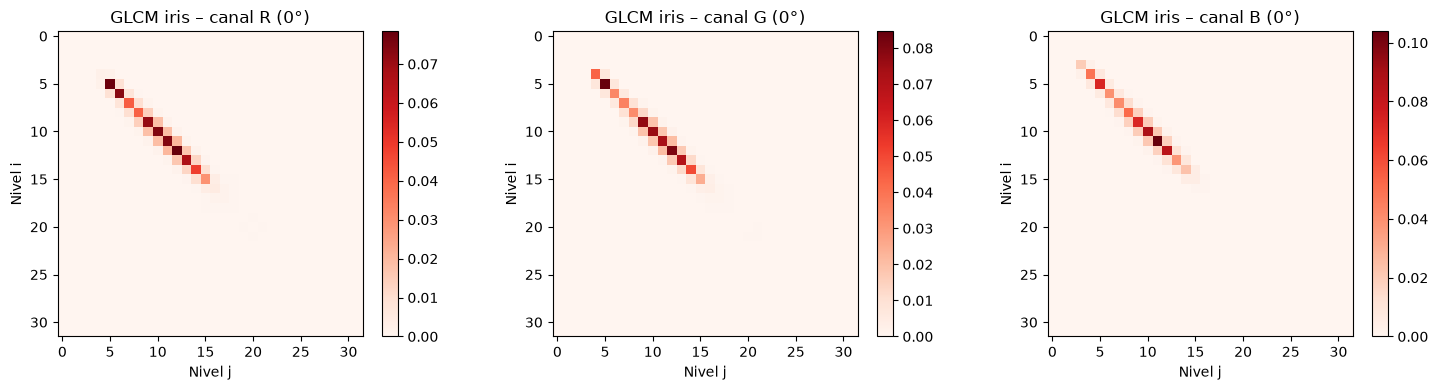

In [58]:
# Visualizar la GLCM del iris para cada canal, a 0°
fig, axs = plt.subplots(1, 3, figsize=(15, 4))

for ax, canal in zip(axs, "RGB"):
    im = ax.imshow(glcms[("Iris", canal)][:, :, 0, 0], cmap="Reds")
    ax.set_title(f"GLCM iris – canal {canal} (0°)")
    ax.set_xlabel("Nivel j"); ax.set_ylabel("Nivel i")
    plt.colorbar(im, ax=ax, fraction=0.046)
    
plt.tight_layout()
plt.show()

Las GLCM del iris presentan patrones similares en los 3 canales. Se observa que los valores de la GLCM se concentran cerca de la diagonal, lo que indica que los píxeles vecinos suelen tener niveles de intensidad similares, lo cual es consistente con los valores altos de homogeneidad y correlación obtenidos.

En cuanto a la riqueza textural del estroma iridiano, el canal R presenta el mayor contraste y la menor homogeneidad entre los 3 canales. Esto muestra que, en este canal, las intensidades de píxeles vecinos tienen variaciones más marcadas, por lo que puede considerarse que es el que muestra mayor riqueza textural.

En comparación con el iris, la pupila presenta mayor homogeneidad y energía, aunque su contraste es similar. Esto indica que los valores de la GLCM de la pupila están más concentrados y tienen una mayor proporción de transiciones entre niveles similares.

A continuación, se aplicará a cada frame del video el procedimiento de segmentación de la pupila desarrollado en el módulo 2, adaptado para procesar una secuencia de imágenes. Esto implica el recorte de una ROI, la conversión a escala de grises y la segmentación mediante Watershed con cierre morfológico.

A partir del contorno obtenido en cada frame, se calcularán el área y el diámetro de la pupila, lo que permite analizar su evolución a lo largo del video.

Para segmentar la pupila en cada frame, se parte del método desarrollado en el módulo 2 (Watershed sobre la ROI con contraste ×1.5 y suavizado gaussiano de 5x5, marcadores de pupila y de fondo, y cierre morfológico). Sin embargo, en el video es necesario adaptar el procedimiento, ya que la pupila cambia de posición y tamaño, y pueden aparecer reflejos del flash y obstrucciones por las pestañas.

Las principales modificaciones son:
- Se estima el centro de la pupila en cada frame mediante una ventana de búsqueda alrededor de la posición anterior. A partir de ese centro se define la ROI.
- Se identifican y atenúan las regiones brillantes cercanas a la pupila para reducir su influencia sobre la segmentación.
- Se utiliza un círculo de radio 10 píxeles como semilla inicial, en lugar del radio 20 utilizado anteriormente, lo que permite adaptar el marcador a las contracciones de la pupila.
- Con ese radio, en algunos frames (por ejemplo cuando se ve el reflejo en la pupila), el Watershed no atraviesa la franja clara y el contorno queda más chico que la pupila. Por eso, además del radio base, se prueban radios de 16 y 22 px y se compara el contraste de borde de cada contorno. Un contorno correcto tiene pupila (oscuro) adentro e iris (claro) afuera, por lo que su contraste es alto.
- Se mantiene el cierre de 5x5 utilizado durante la segmentación. Luego, se aplica una apertura de 11x11 para eliminar prolongaciones finas, un cierre de 21x21 para rellenar pequeños huecos y, finalmente, la envolvente convexa del contorno para regularizar su forma.

In [59]:
X0, Y0, ROI_W, ROI_H = 1120, 470, 320, 130     # mismo recorte del módulo 1

cap = cv2.VideoCapture(VIDEO_PATH)
if not cap.isOpened():
    raise RuntimeError(f"No se pudo abrir el video: {VIDEO_PATH}")

fps = cap.get(cv2.CAP_PROP_FPS)
n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
print(f"FPS: {fps:.2f} | Frames: {n_frames} | Duración: {n_frames / fps:.2f} s")

FPS: 29.98 | Frames: 956 | Duración: 31.89 s


In [60]:
# Parámetros para localizar el centro de la pupila
RADIO_BUSQUEDA = 80
RADIO_BUSQUEDA_INICIAL = 150 # para el primer frame
MARGEN_OSCURO = 15

# Kernels para atenuar reflejos y suavizar la imagen
KERNEL_SUAVIZADO = 31
KERNEL_REFLEJO = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (25, 25))

def seguir_pupila(frame_bgr, centro_previo, radio_busqueda=RADIO_BUSQUEDA):
    h, w = frame_bgr.shape[:2]
    cx, cy = centro_previo
    x0, x1 = max(cx - radio_busqueda, 0), min(cx + radio_busqueda, w)
    y0, y1 = max(cy - radio_busqueda, 0), min(cy + radio_busqueda, h)

    ventana = cv2.cvtColor(frame_bgr[y0:y1, x0:x1], cv2.COLOR_BGR2GRAY)
    ventana = cv2.morphologyEx(ventana, cv2.MORPH_OPEN, KERNEL_REFLEJO)   # borra reflejos brillantes
    ventana = cv2.GaussianBlur(ventana, (KERNEL_SUAVIZADO, KERNEL_SUAVIZADO), 0)
    valor_min, _, punto_min, _ = cv2.minMaxLoc(ventana)

    # Región oscura conectada al mínimo y su centroide
    _, binaria = cv2.threshold(ventana, int(valor_min) + MARGEN_OSCURO, 255, cv2.THRESH_BINARY_INV)
    _, etiquetas = cv2.connectedComponents(binaria)
    region = (etiquetas == etiquetas[punto_min[1], punto_min[0]]).astype(np.uint8)
    M = cv2.moments(region, binaryImage=True)
    return x0 + int(M["m10"] / M["m00"]), y0 + int(M["m01"] / M["m00"])

centro = (X0 + center_x, Y0 + center_y)
centros = []
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

# Se estima el centro de la pupila en cada frame y se almacenan las coordenadas
# para utilizarlas en las etapas siguientes
for i in range(n_frames):
    ok, frame = cap.read()
    if not ok:
        centros.append((np.nan, np.nan)); continue
    radio = RADIO_BUSQUEDA_INICIAL if i == 0 else RADIO_BUSQUEDA
    centro = seguir_pupila(frame, centro, radio)
    centros.append(centro)

centros = np.array(centros, dtype=float)

In [61]:
# Recorta la ROI alrededor de la posición estimada y devuelve el centro expresado
# en coordenadas relativas a la ROI
def recortar_roi(frame_bgr, centro):
    """Recorta una ROI de 320x130 con la pupila en (center_x, center_y), como en el módulo 1."""
    h, w = frame_bgr.shape[:2]
    x0 = int(np.clip(centro[0] - center_x, 0, w - ROI_W))
    y0 = int(np.clip(centro[1] - center_y, 0, h - ROI_H))
    roi = frame_bgr[y0:y0 + ROI_H, x0:x0 + ROI_W]
    return roi, (centro[0] - x0, centro[1] - y0)      # centro dentro de la ROI

In [62]:
# Parámetros para detectar reflejos brillantes próximos a la pupila
UMBRAL_REFLEJO = 200
RADIO_ZONA_REFLEJO = 45

# Se amplía la máscara para incluir los bordes de los reflejos
KERNEL_DILATAR_REFLEJO = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))

def quitar_reflejos(gris, cx, cy):
    """Rellena los reflejos brillantes cercanos a la pupila con los píxeles de alrededor."""
    _, brillo = cv2.threshold(gris, UMBRAL_REFLEJO, 255, cv2.THRESH_BINARY)
    brillo = cv2.dilate(brillo, KERNEL_DILATAR_REFLEJO)
    cerca = np.zeros(gris.shape, np.uint8)
    cv2.circle(cerca, (int(cx), int(cy)), RADIO_ZONA_REFLEJO, 255, -1)
    brillo = cv2.bitwise_and(brillo, cerca)
    return cv2.inpaint(gris, brillo, 5, cv2.INPAINT_TELEA)

In [64]:
# Radios posibles para el marcador inicial de Watershed
RADIOS_MARCADOR = (10, 16, 22)

# Kernels para eliminar prolongaciones finas y rellenar huecos
MARGEN_CONTRASTE = 8
KERNEL_COLITAS = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11))
KERNEL_CIERRE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (21, 21))

def contorno_con_marcador(limpia, cx, cy, radio):
    """Watershed + apertura + cierre + envolvente convexa con un radio de marcador dado."""
    try:
        mascara, _ = segmentar_pupila(limpia, cx=cx, cy=cy, radio=radio)
    except ValueError:
        return None
    mascara = cv2.morphologyEx(mascara, cv2.MORPH_OPEN, KERNEL_COLITAS)
    mascara = cv2.morphologyEx(mascara, cv2.MORPH_CLOSE, KERNEL_CIERRE)
    contornos, _ = cv2.findContours(mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if not contornos:
        return None
    return cv2.convexHull(max(contornos, key=cv2.contourArea))

def contraste_borde(gris, contorno, ancho=4):
    """Gris medio del anillo exterior menos el del anillo interior del contorno."""
    mascara = np.zeros(gris.shape, np.uint8)
    cv2.drawContours(mascara, [contorno], -1, 255, -1)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * ancho + 1, 2 * ancho + 1))
    anillo_ext = cv2.subtract(cv2.dilate(mascara, k), mascara)
    anillo_int = cv2.subtract(mascara, cv2.erode(mascara, k))
    return cv2.mean(gris, mask=anillo_ext)[0] - cv2.mean(gris, mask=anillo_int)[0]

def medir_pupila(roi_gris, cx=center_x, cy=center_y):
    """Devuelve el contorno de la pupila o None si no segmenta nada."""
    limpia = quitar_reflejos(roi_gris, cx, cy)
    mejor = contorno_con_marcador(limpia, cx, cy, RADIOS_MARCADOR[0])
    if mejor is None:
        return None
    mejor_c = contraste_borde(limpia, mejor)
    # Se prueban los distintos radios y se conserva el contorno que
    # mejora suficientemente el contraste del borde
    for radio in RADIOS_MARCADOR[1:]:
        cand = contorno_con_marcador(limpia, cx, cy, radio)
        if cand is None:
            continue
        c = contraste_borde(limpia, cand)
        if c > mejor_c + MARGEN_CONTRASTE:       # solo reemplaza si mejora claramente
            mejor, mejor_c = cand, c
    return mejor

In [63]:
def circularidad(contorno):
    """Mide qué tan circular es el contorno: se aproxima a 1 para una circunferencia ideal"""
    area = cv2.contourArea(contorno)
    perimetro = cv2.arcLength(contorno, True)
    return 4 * np.pi * area / perimetro**2


Como verificación de que la segmentación generaliza a todo el video, se evalúa en 12 frames.

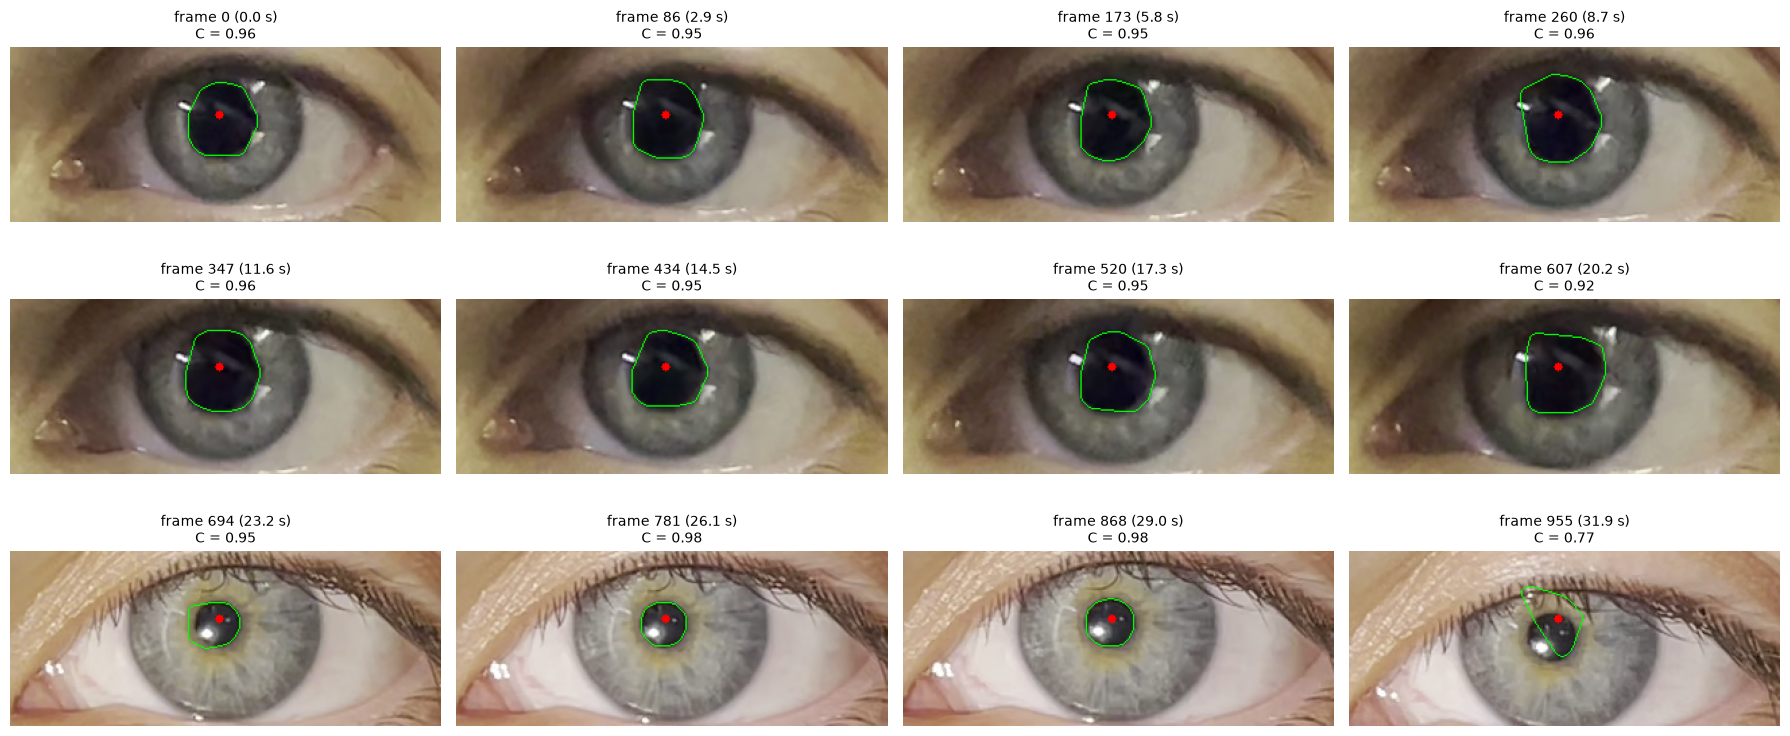

In [ ]:
# Selección de frames distribuidos
indices = np.linspace(0, n_frames - 1, 12).astype(int)

fig, axs = plt.subplots(3, 4, figsize=(18, 8))
for ax, idx in zip(axs.ravel(), indices):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
    ok, frame = cap.read()

    centro_i = (int(centros[idx, 0]), int(centros[idx, 1]))
    roi, (cx, cy) = recortar_roi(frame, centro_i)
    gris = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)
    vis = cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)

    contorno = medir_pupila(gris, cx=cx, cy=cy)
    if contorno is None:
        titulo = f"frame {idx}: sin segmentación"
    else:
        cv2.drawContours(vis, [contorno], -1, (0, 255, 0), 1)
        titulo = f"frame {idx} ({idx / fps:.1f} s)\nC = {circularidad(contorno):.2f}"
    cv2.circle(vis, (cx, cy), 3, (255, 0, 0), -1)
    ax.imshow(vis); ax.set_title(titulo, fontsize=10); ax.axis("off")
plt.tight_layout()
plt.show()

La visualización de distintos frames permite evaluar el comportamiento del método de segmentación a lo largo del video. Se busca que el contorno obtenido se ajuste a la pupila, aunque pueden aparecer errores en algunos frames debido a parpadeos, reflejos u otros artefactos.

Para complementar la evaluación visual, se utiliza el parámetro de circularidad. La evolución de este parámetro a lo largo del video puede ayudar a identificar frames con posibles errores de segmentación. Este parámetro se usa como indicador complementario, no como una medida definitiva de la calidad del contorno.

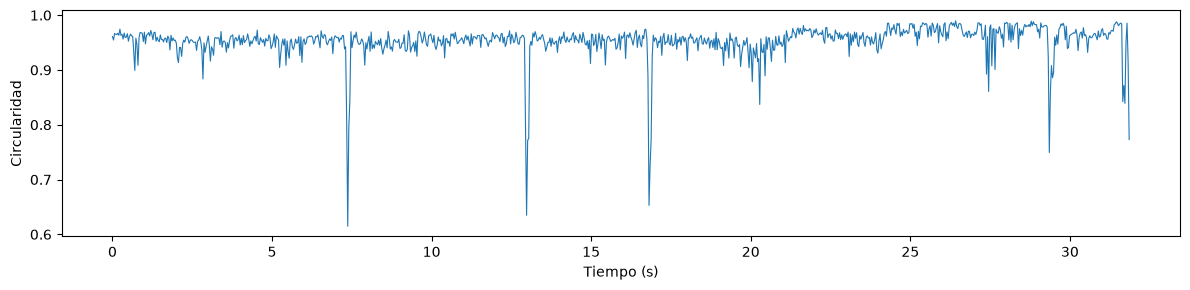

In [67]:
# Circularidad frame a frame
filas = []
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)     # volver al primer frame
for i in range(n_frames):
    ok, frame = cap.read()
    if not ok or np.isnan(centros[i, 0]):
        filas.append((i, i / fps, np.nan)); continue
    roi, (cx, cy) = recortar_roi(frame, (int(centros[i, 0]), int(centros[i, 1])))
    contorno = medir_pupila(cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY), cx=cx, cy=cy)
    filas.append((i, i / fps, np.nan if contorno is None else circularidad(contorno)))

df = pd.DataFrame(filas, columns=["frame", "t (s)", "Circularidad"])

# Evolución temporal
plt.figure(figsize=(12, 3))
plt.plot(df["t (s)"], df["Circularidad"], linewidth=0.8)
plt.xlabel("Tiempo (s)"); plt.ylabel("Circularidad")
plt.tight_layout()
plt.show()

La circularidad se mantiene aproximadamente constante, con caídas puntuales que probablemente corresponden a parpadeos o movimientos (artefactos). Se consideran inválidos los frames con circularidad < 0,89, ya que por debajo de ese valor los contornos de los frames analizados dejan de ajustarse a la pupila. Estos frames se excluyen del análisis y se reemplazan por interpolación.

Frames inválidos: 24 de 956 (2.5 %)


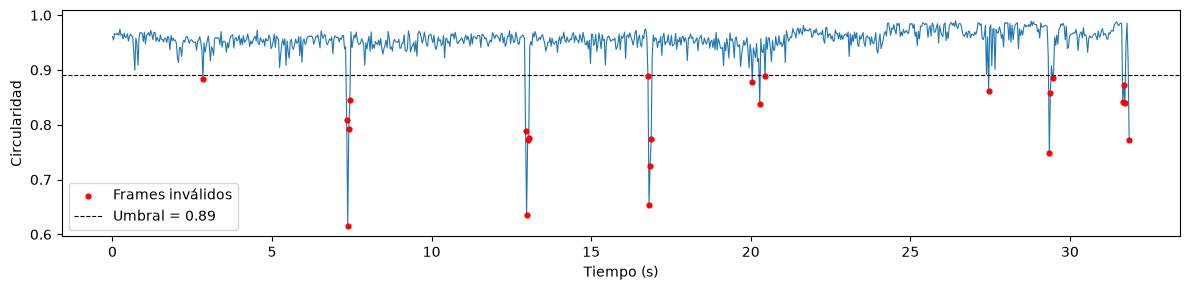

In [68]:
UMBRAL_CIRC = 0.89

df["Válido"] = df["Circularidad"] >= UMBRAL_CIRC     # NaN queda como inválido
print(f"Frames inválidos: {(~df['Válido']).sum()} de {len(df)} "
      f"({100 * (~df['Válido']).mean():.1f} %)")

plt.figure(figsize=(12, 3))
plt.plot(df["t (s)"], df["Circularidad"], linewidth=0.8)
plt.scatter(df.loc[~df["Válido"], "t (s)"], df.loc[~df["Válido"], "Circularidad"],
            color="r", s=12, zorder=3, label="Frames inválidos")
plt.axhline(UMBRAL_CIRC, color="k", linestyle="--", linewidth=0.8, label=f"Umbral = {UMBRAL_CIRC}")
plt.xlabel("Tiempo (s)"); plt.ylabel("Circularidad"); plt.legend()
plt.tight_layout(); plt.show()

A continuación se calculará el área y el diametro frame a frame.

In [70]:
filas = []
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
for i in range(n_frames):
    ok, frame = cap.read()
    if not ok or np.isnan(centros[i, 0]):
        filas.append((i, i / fps, np.nan, np.nan, np.nan)); continue
    roi, (cx, cy) = recortar_roi(frame, (int(centros[i, 0]), int(centros[i, 1])))
    contorno = medir_pupila(cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY), cx=cx, cy=cy)
    if contorno is None:
        filas.append((i, i / fps, np.nan, np.nan, np.nan)); continue
    area = cv2.contourArea(contorno)
    diametro = 2 * np.sqrt(area / np.pi)
    filas.append((i, i / fps, area, diametro, circularidad(contorno)))

df = pd.DataFrame(filas, columns=["frame", "t (s)", "Área auto (px²)", "Diámetro auto (px)", "Circularidad"])
df["Válido"] = df["Circularidad"] >= UMBRAL_CIRC            # NaN queda como inválido

# Se anulan los valores inválidos y se rellenan por interpolación lineal
# También se rellenan los extremos
df["Área (px²)"] = df["Área auto (px²)"].where(df["Válido"]).interpolate(method="linear", limit_direction="both")
df["Diámetro (px)"] = df["Diámetro auto (px)"].where(df["Válido"]).interpolate(method="linear", limit_direction="both")
df["Interpolado"] = ~df["Válido"]

inv = ~df["Válido"]

# Se cuenta el largo de cada grupo inválido para saber cuántos frames seguidos se interpolaron
rachas = inv.ne(inv.shift()).cumsum()[inv].value_counts()
print(f"Frames interpolados: {inv.sum()} de {len(df)} ({100 * inv.mean():.1f} %) | racha más larga: {rachas.max()} frames ({rachas.max() / fps:.2f} s)")

Frames interpolados: 24 de 956 (2.5 %) | racha más larga: 4 frames (0.13 s)


A continuación se anotan 15 frames equiespaciados, en cada uno se marcan manualmente al menos 5 puntos del borde de la pupila y se ajusta una elipse. Estos datos se guardan en CSV y se compara con los datos tomados de la segmentación automática.

In [74]:
import os
ANOT_PATH = "../data/reference/anotaciones_manuales.csv"
ESCALA = 4
frames_manual = np.linspace(0, n_frames - 1, 15).astype(int)

def anotar_frame(idx):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx)); ok, frame = cap.read()
    roi, _ = recortar_roi(frame, (int(centros[idx, 0]), int(centros[idx, 1])))
    grande = cv2.resize(roi, None, fx=ESCALA, fy=ESCALA, interpolation=cv2.INTER_CUBIC)
    puntos = []
    def click(ev, x, y, flags, param):
        if ev == cv2.EVENT_LBUTTONDOWN: puntos.append((x, y))
    ventana = f"frame {idx} - clic en el borde (min 5) | Enter: aceptar | u: deshacer | s: saltear"
    cv2.namedWindow(ventana); cv2.setMouseCallback(ventana, click)
    while True:
        vis = grande.copy()
        for p in puntos: cv2.circle(vis, p, 3, (0, 0, 255), -1)
        if len(puntos) >= 5:
            cv2.ellipse(vis, cv2.fitEllipse(np.array(puntos, np.float32)), (0, 255, 0), 1)
        cv2.imshow(ventana, vis)
        k = cv2.waitKey(20) & 0xFF
        if k == 13 and len(puntos) >= 5: break
        if k == ord("u") and puntos: puntos.pop()
        if k == ord("s"): puntos = None; break
    cv2.destroyAllWindows(); cv2.waitKey(1)
    if puntos is None: return None
    (_, _), (d1, d2), _ = cv2.fitEllipse(np.array(puntos, np.float32) / ESCALA)
    area = np.pi * d1 * d2 / 4
    return area, 2 * np.sqrt(area / np.pi)

# Se retoma desde lo que ya esté anotado
manual = pd.read_csv(ANOT_PATH) if os.path.exists(ANOT_PATH) else pd.DataFrame(columns=["frame", "Área manual (px²)", "Diámetro manual (px)"])
for idx in frames_manual:
    if idx in manual["frame"].values: continue
    res = anotar_frame(idx)
    if res is not None:
        manual.loc[len(manual)] = [idx, *res]
        manual.to_csv(ANOT_PATH, index=False)

,n,MAE,RMSE,Sesgo (auto−manual),Error relativo medio (%)
Área (px²),15.0,100.21,125.06,29.17,6.05
Diámetro (px),15.0,1.32,1.69,0.51,2.97


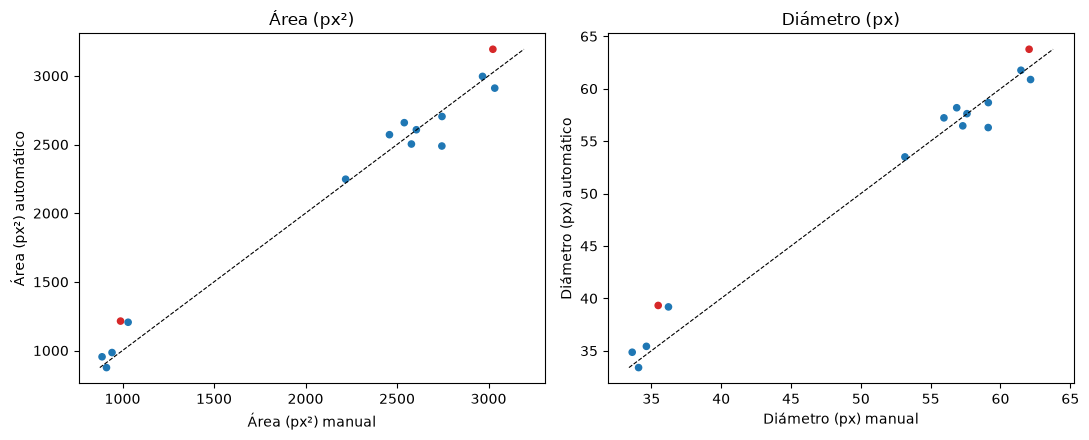

In [75]:
manual = pd.read_csv(ANOT_PATH)
manual = manual[manual["frame"].isin(frames_manual)]
comp = manual.merge(df, on="frame")

def metricas(auto, man):
    e = auto - man
    return {"n": len(e), "MAE": e.abs().mean(), "RMSE": np.sqrt((e**2).mean()),
            "Sesgo (auto−manual)": e.mean(), "Error relativo medio (%)": 100 * (e.abs() / man).mean()}

tabla = pd.DataFrame({
    "Área (px²)":    metricas(comp["Área (px²)"], comp["Área manual (px²)"]),
    "Diámetro (px)": metricas(comp["Diámetro (px)"], comp["Diámetro manual (px)"]),
}).T
display(tabla.round(2))

fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (auto, man) in zip(axs, [("Área (px²)", "Área manual (px²)"),
                                ("Diámetro (px)", "Diámetro manual (px)")]):
    ax.scatter(comp[man], comp[auto], c=np.where(comp["Interpolado"], "tab:red", "tab:blue"), s=20)
    lim = [min(comp[man].min(), comp[auto].min()), max(comp[man].max(), comp[auto].max())]
    ax.plot(lim, lim, "k--", linewidth=0.8)
    ax.set_xlabel(f"{auto} manual"); ax.set_ylabel(f"{auto} automático"); ax.set_title(auto)
plt.tight_layout(); plt.show()

In [76]:
from IPython.display import Markdown

d, a = tabla.loc["Diámetro (px)"], tabla.loc["Área (px²)"]
# Punto con mayor error en diámetro y si corresponde a un frame interpolado
peor = comp.loc[(comp["Diámetro (px)"] - comp["Diámetro manual (px)"]).abs().idxmax()]

display(Markdown(
    f"Con {int(d['n'])} frames anotados, el error relativo medio es "
    f"**{d['Error relativo medio (%)']:.1f} %** en el diámetro y "
    f"**{a['Error relativo medio (%)']:.1f} %** en el área. "
    f"El sesgo (auto−manual) es {d['Sesgo (auto−manual)']:.2f} px en el diámetro. "
    f"El frame con mayor error es el {int(peor['frame'])} "
    f"({'interpolado' if peor['Interpolado'] else 'no interpolado'})."
))

Con 15 frames anotados, el error relativo medio es **3.0 %** en el diámetro y **6.1 %** en el área. El sesgo (auto−manual) es 0.51 px en el diámetro. El frame con mayor error es el 955 (interpolado).

La segmentación automática concuerda con la medición manual en los frames anotados: los errores porcentuales son bajos y el sesgo es pequeño (ver valores arriba). Se considera que la segmentación es adecuada para calcular las curvas temporales.

A continuación se grafican el diámetro D(t) y el área A(t) de la pupila a lo largo del video. En rojo se marcan los frames que se interpolaron.

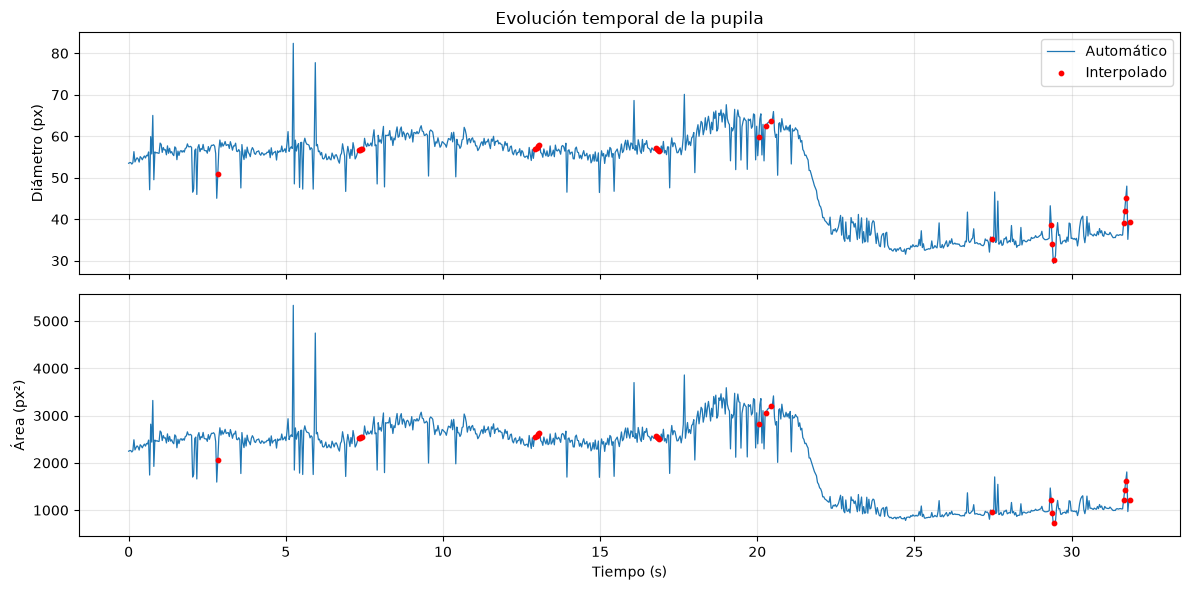

In [77]:
fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

interp = df[df["Interpolado"]]
for ax, col in zip(axs, ["Diámetro (px)", "Área (px²)"]):
    ax.plot(df["t (s)"], df[col], linewidth=0.9, label="Automático")
    ax.scatter(interp["t (s)"], interp[col], color="r", s=10, zorder=3, label="Interpolado")
    ax.set_ylabel(col)
    ax.grid(alpha=0.3)

axs[0].legend(loc="upper right")
axs[1].set_xlabel("Tiempo (s)")
axs[0].set_title("Evolución temporal de la pupila")
plt.tight_layout()
plt.show()

En la curva se observa que el diámetro de la pupila se mantiene en torno a 55–60 px (área de ~2500 px²) durante los primeros ~21 s y luego disminuye de forma marcada, hasta estabilizarse en ~35 px (área de ~1000 px²) a partir de los ~23 s. Esta caída corresponde a la constricción de la pupila. Los picos aislados, probablemente se deban a artefactos u otros ruidos no detectados anteriormente por el criterio de circularidad, como parpadeos o errores puntuales de segmentación.

Para calcular la latencia, buscamos el intervalo entre la aplicación del flash y el inicio de la constricción de la pupila.
El inicio del estímulo se detecta como el instante en el que el brillo medio del video supera el 10% de su subida total, y el inicio de la constricción como el primer instante en que el diámetro cae más de un 10% por debajo de la línea de la mediana de todo el tramo previo al estímulo y se mantiene así durante 5 frames consecutivos.

La amplitud es la diferencia entre el área basal y el área mínima de la serie suavizada.

El mismo criterio de inicio (desviación del 10% sostenida durante 5 frames) se aplica tanto a la velocidad de constricción como para la de redilatación.

Este criterio se aplica porque no produce falsos inicios en el tramo previo al estímulo en ninguno de los registros, mientras que umbrales menores (5% o 2σ) detectan falsas constricciones

In [126]:
FRAC_INICIO = 0.10     # el inicio de un cambio (constricción o redilatación) es una desviación del 10 % respecto del nivel previo
N_SOSTENIDO = 5
VENT_MIN = 15

def inicio_cambio(d, i_ini, nivel_ref, frac=FRAC_INICIO, sentido=-1, n_sostenido=N_SOSTENIDO):
    """Primer frame desde i_ini que abre una racha de n_sostenido frames con el diámetro apartado más de
    frac del nivel de referencia. sentido=-1: caída (constricción); sentido=+1: subida (redilatación)."""
    umbral = nivel_ref * (1 + sentido * frac)
    fuera = d < umbral if sentido < 0 else d > umbral
    for i in range(i_ini, len(d) - n_sostenido + 1):
        if fuera[i:i + n_sostenido].all():
            return i
    return None

In [127]:
def detectar_estimulo(df_v, cap_v, n_frames_v):
    """Frame aproximado del estímulo (referencia para inicio_rampa, que fija el instante exacto con el criterio del 10%). Agrega la columna 'Brillo' a df_v."""
    # Brillo medio de cada frame
    brillo = []
    cap_v.set(cv2.CAP_PROP_POS_FRAMES, 0)
    for i in range(n_frames_v):
        ok, frame = cap_v.read()
        if not ok:
            brillo.append(np.nan); continue
        chico = cv2.resize(frame, None, fx=0.1, fy=0.1, interpolation=cv2.INTER_AREA)
        brillo.append(cv2.mean(cv2.cvtColor(chico, cv2.COLOR_BGR2GRAY))[0])
    df_v["Brillo"] = brillo

    # Frame del mayor salto de brillo
    b = df_v["Brillo"].rolling(5, center=True, min_periods=1).median()
    salto = b.diff(5).abs()
    i_pico = int(salto.idxmax())

    # Estadísticas del brillo previo al flash
    base = df_v["Brillo"].iloc[max(0, i_pico - 60): i_pico - 10]
    mu, sd = base.median(), base.std()

    # Umbral de brillo
    umbral = mu + max(3 * sd, 0.05 * (df_v["Brillo"].iloc[i_pico] - mu))

    # Primer frame que supera ese umbral en la ventana de 15 frames
    ini = max(0, i_pico - 15)
    return ini + int(np.argmax(df_v["Brillo"].iloc[ini:i_pico + 1].values > umbral))

In [105]:
def inicio_rampa(df_v, fps_v, i_ref, frac=0.10):
    """Frame en que el brillo supera frac (p. ej. 10 %) de su subida total, buscando hacia atrás desde el 50 % de la subida.
    i_ref: frame aproximado del estímulo (el que devuelve detectar_estimulo)."""
    b = df_v["Brillo"].rolling(3, center=True, min_periods=1).median().values
    n1, n3, n15 = int(round(fps_v)), int(round(3 * fps_v)), int(round(1.5 * fps_v))
    base = np.median(b[i_ref - n3: i_ref - n1])                  # nivel previo al flash (entre 3 s y 1 s antes)
    pico = b[i_ref: i_ref + n15].max()

    # Primer frame donde el brillo llega al 50% de la subida
    i50 = i_ref - n1 + int(np.argmax(b[i_ref - n1: i_ref + n15] >= base + 0.5 * (pico - base)))
    i = i50

    # Retrocede hasta cruzar el 10%
    while i > 0 and b[i] > base + frac * (pico - base):
        i -= 1
    return i + 1

In [137]:
def analizar_registro(df_v, cap_v, fps_v, i_estimulo=None, frac_caida=FRAC_INICIO, frac_rampa=0.10,
                      n_sostenido=N_SOSTENIDO, vent_min=VENT_MIN):
    """Estímulo, latencia y amplitud de un registro, con los mismos criterios para cualquier video.
    Requiere las columnas 't (s)', 'Diámetro (px)' y 'Área (px²)' de df_v (salida de procesar_video).
    i_estimulo: frame aproximado del estímulo (el de detectar_estimulo); si es None se detecta acá."""
    n_v = len(df_v)

    # Estímulo: frame aproximado por salto de brillo -> inicio de la rampa (frac_rampa de la subida)
    #    i_estimulo (parámetro) es el frame aproximado; i_est es el inicio de la rampa y es el que se usa de acá en adelante
    if i_estimulo is None or "Brillo" not in df_v.columns:
        i_det = detectar_estimulo(df_v, cap_v, n_v)        # también crea la columna 'Brillo'
        i_estimulo = i_det if i_estimulo is None else i_estimulo
    if i_estimulo < round(3 * fps_v):
        raise ValueError("El estímulo ocurre en los primeros 3 s del video: no hay línea base suficiente.")
    i_est = inicio_rampa(df_v, fps_v, i_estimulo, frac_rampa)
    t0 = df_v.loc[i_est, "t (s)"]

    # Latencia: primer frame desde el estímulo que abre una racha de n_sostenido frames
    #    con el diámetro por debajo de (1 - frac_caida) * línea base (mediana de todo el tramo previo)
    d = df_v["Diámetro (px)"].values
    base_d = np.nanmedian(d[:i_est])
    umbral_d = base_d * (1 - frac_caida)                   # solo para graficar; inicio_cambio lo recalcula
    i_constr = inicio_cambio(d, i_est, base_d, frac_caida, -1, n_sostenido)

    # Amplitud: área basal (mediana de todo el tramo previo) menos el área mínima de la serie suavizada
    a_suav = df_v["Área (px²)"].rolling(vent_min, center=True, min_periods=1).median()
    area_basal = a_suav.iloc[:i_est].median()
    if i_constr is None:
        # no hubo constricción sostenida: todos los resultados quedan en NaN
        lat_ms = lat_fr = t_constr = i_min = area_min = amplitud = amp_pct = np.nan
    else:
        t_constr = df_v.loc[i_constr, "t (s)"]
        lat_ms, lat_fr = (t_constr - t0) * 1000, i_constr - i_est
        i_min = i_constr + int(np.argmin(a_suav.values[i_constr:]))   # mínimo desde la constricción hasta el final
        area_min = a_suav.iloc[i_min]
        amplitud = area_basal - area_min
        amp_pct = 100 * amplitud / area_basal

    return {"i_estimulo": i_est, "t_estimulo": t0, "base_diam": base_d, "umbral_diam": umbral_d,
            "i_constr": i_constr, "t_constr": t_constr, "latencia_ms": lat_ms, "latencia_frames": lat_fr,
            "area_basal": area_basal, "area_min": area_min, "i_min": i_min,
            "t_min": df_v.loc[i_min, "t (s)"] if i_constr is not None else np.nan,
            "amplitud": amplitud, "amplitud_pct": amp_pct}

In [138]:
def graficar_analisis(df_v, r, nombre=""):
    fig, axs = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
    axs[0].plot(df_v["t (s)"], df_v["Diámetro (px)"], linewidth=0.9)
    axs[0].axhline(r["umbral_diam"], color="gray", ls=":", label="Umbral de caída")
    axs[0].set_ylabel("Diámetro (px)"); axs[0].set_title(nombre)
    axs[1].plot(df_v["t (s)"], df_v["Área (px²)"], linewidth=0.9)
    axs[1].axhline(r["area_basal"], color="gray", ls=":", label="Área basal")
    if not np.isnan(r["area_min"]):
        axs[1].axhline(r["area_min"], color="gray", ls="--", label="Área mínima")
    axs[1].set_ylabel("Área (px²)"); axs[1].set_xlabel("Tiempo (s)")
    for ax in axs:
        ax.axvline(r["t_estimulo"], color="r", ls="--", linewidth=0.9, label="Estímulo")
        if not np.isnan(r["t_constr"]):
            ax.axvline(r["t_constr"], color="g", ls="--", linewidth=0.9, label="Inicio de la constricción")
        ax.grid(alpha=0.3); ax.legend(loc="upper right", fontsize=8)
    plt.tight_layout(); plt.show()
    
def mostrar_analisis(df_v, r, nombre=""):
    """Mismo resumen y mismas figuras para cualquier registro (r: salida de analizar_registro)."""
    print(nombre)
    print(f"Estímulo:                  frame {r['i_estimulo']} ({r['t_estimulo']:.3f} s)")
    print(f"Inicio de la constricción: frame {r['i_constr']} ({r['t_constr']:.3f} s)")
    print(f"Tiempo de latencia: {r['latencia_ms']:.0f} ms ({r['latencia_frames']} frames)")
    print(f"Línea base: {r['base_diam']:.1f} px | umbral de caída: {r['umbral_diam']:.1f} px")
    print(f"Área basal:  {r['area_basal']:.0f} px²")
    print(f"Área mínima: {r['area_min']:.0f} px² (frame {r['i_min']}, {r['t_min']:.2f} s)")
    print(f"Amplitud de respuesta: {r['amplitud']:.0f} px² ({r['amplitud_pct']:.1f} % del área basal)")

    fig, axs = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
    axs[0].plot(df_v["t (s)"], df_v["Brillo"], linewidth=0.9); axs[0].set_ylabel("Brillo medio del frame")
    axs[1].plot(df_v["t (s)"], df_v["Diámetro (px)"], linewidth=0.9); axs[1].set_ylabel("Diámetro (px)")
    for ax in axs:
        ax.axvline(r["t_estimulo"], color="r", linestyle="--", linewidth=0.9); ax.grid(alpha=0.3)
    axs[0].set_title(f"{nombre}: estímulo detectado"); axs[1].set_xlabel("Tiempo (s)")
    plt.tight_layout(); plt.show()
    graficar_analisis(df_v, r, nombre)

Registro A_2
Estímulo:                  frame 639 (21.316 s)
Inicio de la constricción: frame 651 (21.716 s)
Tiempo de latencia: 400 ms (12 frames)
Línea base: 57.3 px | umbral de caída: 51.6 px
Área basal:  2570 px²
Área mínima: 832 px² (frame 734, 24.48 s)
Amplitud de respuesta: 1737 px² (67.6 % del área basal)


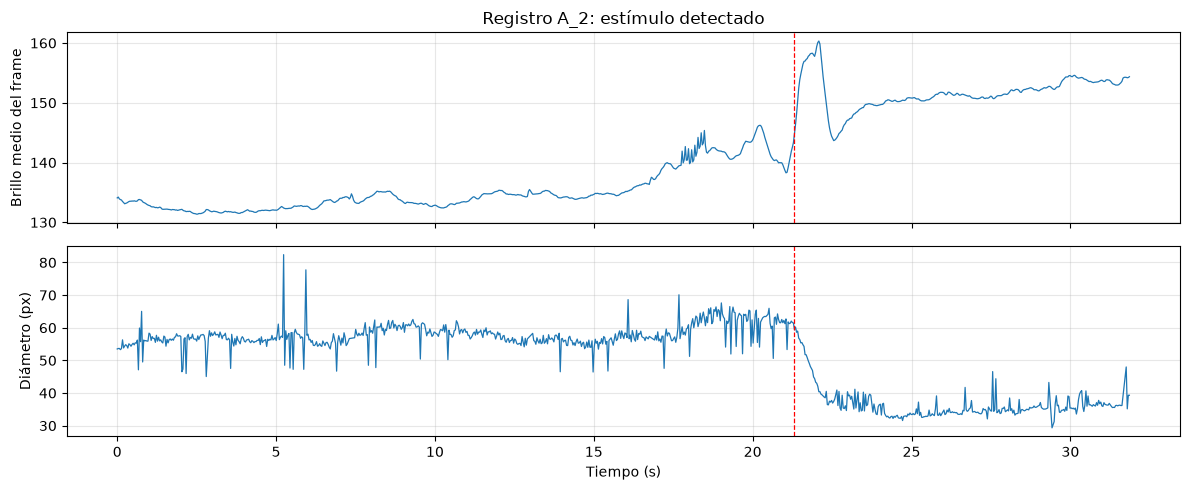

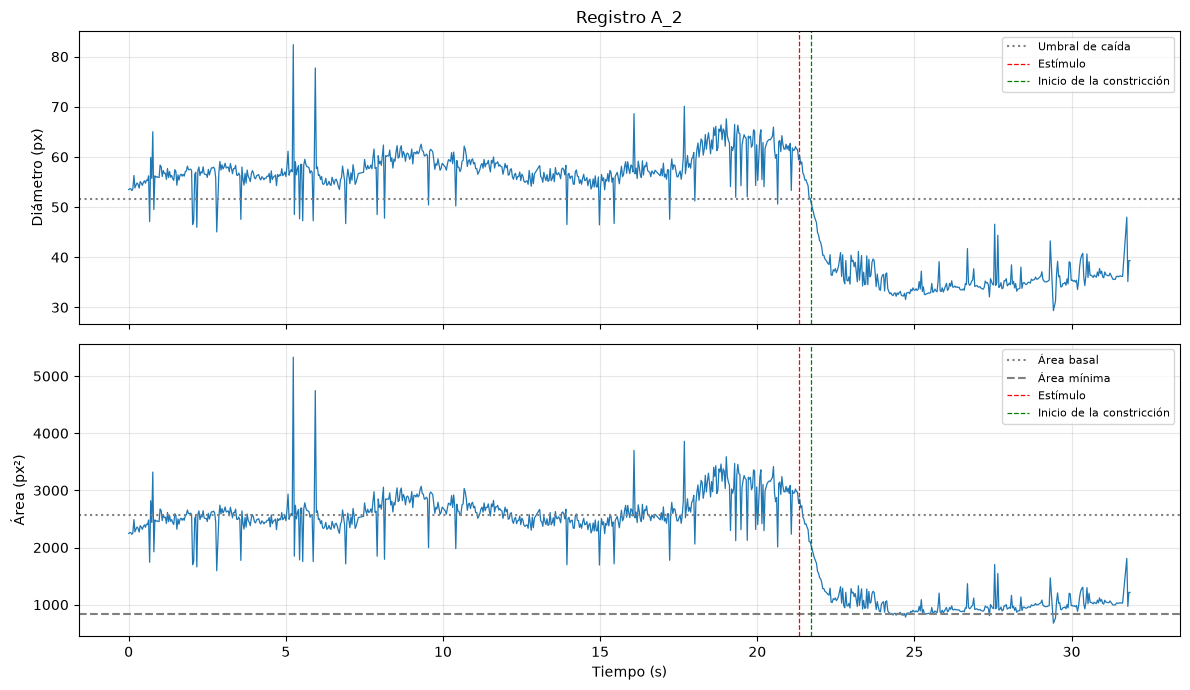

In [139]:
an1 = analizar_registro(df, cap, fps)
mostrar_analisis(df, an1, "Registro A_2")

# Variables que usa la celda de velocidad de constricción (mismo inicio que la latencia)
i_estimulo, T_ESTIMULO = an1["i_estimulo"], an1["t_estimulo"]
i_constr, T_CONSTRICCION = an1["i_constr"], an1["t_constr"]


Cabe aclarar que todos los valores de área y diámetro están expresados en píxeles, no en unidades físicas. Por eso no es del todo seguro guiarse por los valores absolutos: si durante la toma la cámara se acercó o se alejó del ojo, o el ojo cambió de distancia respecto de ella, el tamaño aparente de la pupila en la imagen pudo variar y modificar los resultados, sin que eso corresponda a un cambio real de la pupila.

A continuación, calcularemos la velocidad media de constricción, que se obtiene como el cambio de diámetro entre el inicio de la constricción y el instante en que se completa el 90% de la caída total, dividido por el tiempo entre ambos instantes.

In [140]:
FRAC_CAIDA = 0.9   # fracción de la caída total que marca el final de la constricción

def constriccion(serie):
    s = serie.rolling(VENT_MIN, center=True, min_periods=1).median()
    base = s.iloc[:i_estimulo].median()             # nivel previo al estímulo
    minimo = s.iloc[i_constr:].min()                # mínimo después del inicio de la constricción
    nivel = base - FRAC_CAIDA * (base - minimo)     # diámetro que marca el 90% de la caída
    i_fin = i_constr + int(np.argmax(s.iloc[i_constr:].values <= nivel))   # primer frame que llega al 90 % de la caída
    return s, base, minimo, i_fin

def velocidad_media_constriccion(serie, unidad):
    s, base, minimo, i_fin = constriccion(serie)
    dur = df.loc[i_fin, "t (s)"] - T_CONSTRICCION
    vel = (s.iloc[i_constr] - s.iloc[i_fin]) / dur
    return pd.DataFrame({
        f"Basal ({unidad})": [base],
        f"Mínimo ({unidad})": [minimo],
        "Duración (s)": [dur],
        f"Velocidad media ({unidad}/s)": [vel],
        "Velocidad relativa (% del basal/s)": [100 * vel / base],
    }, index=[""])

display(velocidad_media_constriccion(df["Diámetro (px)"], "px").round(2))

,Basal (px),Mínimo (px),Duración (s),Velocidad media (px/s),Velocidad relativa (% del basal/s)
,57.2,32.56,2.27,7.01,12.26


Se obtiene una velocidad de constricción de 7,01 px/s.

Para calcular la velocidad de redilatación se utiliza otro video. Repetimos todo el procesamiento aplicado al primer video para poder obtener los datos.

FPS: 29.98 | Frames: 615 | Duración: 20.52 s


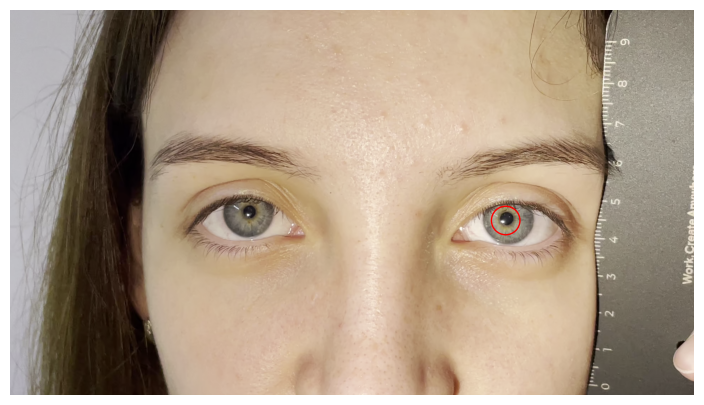

In [141]:
VIDEO_PATH_2 = "../data/raw/Registro B_1.MOV"

cap2 = cv2.VideoCapture(VIDEO_PATH_2)
if not cap2.isOpened():
    raise RuntimeError(f"No se pudo abrir el video: {VIDEO_PATH_2}")
fps2 = cap2.get(cv2.CAP_PROP_FPS)
n_frames2 = int(cap2.get(cv2.CAP_PROP_FRAME_COUNT))
print(f"FPS: {fps2:.2f} | Frames: {n_frames2} | Duración: {n_frames2 / fps2:.2f} s")

CENTRO_INICIAL_2 = (1390, 590)
RADIO_INICIAL_2 = 40

cap2.set(cv2.CAP_PROP_POS_FRAMES, 0)
ok, frame0 = cap2.read()
plt.figure(figsize=(10, 5))
plt.imshow(cv2.cvtColor(frame0, cv2.COLOR_BGR2RGB))
plt.gca().add_patch(plt.Circle(CENTRO_INICIAL_2, RADIO_INICIAL_2, fill=False, color="r"))
plt.axis("off"); plt.show()

In [142]:
def procesar_video(cap_v, n_v, fps_v, centro_inicial, radio_inicial):
    centros_v, centro = [], centro_inicial
    cap_v.set(cv2.CAP_PROP_POS_FRAMES, 0)
    for i in range(n_v):
        ok, frame = cap_v.read()
        if not ok:
            centros_v.append((np.nan, np.nan)); continue
        centro = seguir_pupila(frame, centro, radio_inicial if i == 0 else RADIO_BUSQUEDA)
        centros_v.append(centro)
    centros_v = np.array(centros_v, dtype=float)

    # Medición frame a frame
    filas = []
    cap_v.set(cv2.CAP_PROP_POS_FRAMES, 0)
    for i in range(n_v):
        ok, frame = cap_v.read()
        if not ok or np.isnan(centros_v[i, 0]):
            filas.append((i, i / fps_v, np.nan, np.nan, np.nan)); continue
        roi, (cx, cy) = recortar_roi(frame, (int(centros_v[i, 0]), int(centros_v[i, 1])))
        contorno = medir_pupila(cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY), cx=cx, cy=cy)
        if contorno is None:
            filas.append((i, i / fps_v, np.nan, np.nan, np.nan)); continue
        area = cv2.contourArea(contorno)
        filas.append((i, i / fps_v, area, 2 * np.sqrt(area / np.pi), circularidad(contorno)))

    d = pd.DataFrame(filas, columns=["frame", "t (s)", "Área auto (px²)", "Diámetro auto (px)", "Circularidad"])
    d["Válido"] = d["Circularidad"] >= UMBRAL_CIRC
    d["Área (px²)"] = d["Área auto (px²)"].where(d["Válido"]).interpolate(method="linear", limit_direction="both")
    d["Diámetro (px)"] = d["Diámetro auto (px)"].where(d["Válido"]).interpolate(method="linear", limit_direction="both")
    d["Interpolado"] = ~d["Válido"]
    return d, centros_v

df2, centros2 = procesar_video(cap2, n_frames2, fps2, CENTRO_INICIAL_2, RADIO_INICIAL_2)

inv = ~df2["Válido"]
rachas = inv.ne(inv.shift()).cumsum()[inv].value_counts()
print(f"Frames interpolados: {inv.sum()} de {len(df2)} ({100 * inv.mean():.1f} %) | "
      f"racha más larga: {rachas.max()} frames ({rachas.max() / fps2:.2f} s)")

Frames interpolados: 8 de 615 (1.3 %) | racha más larga: 4 frames (0.13 s)


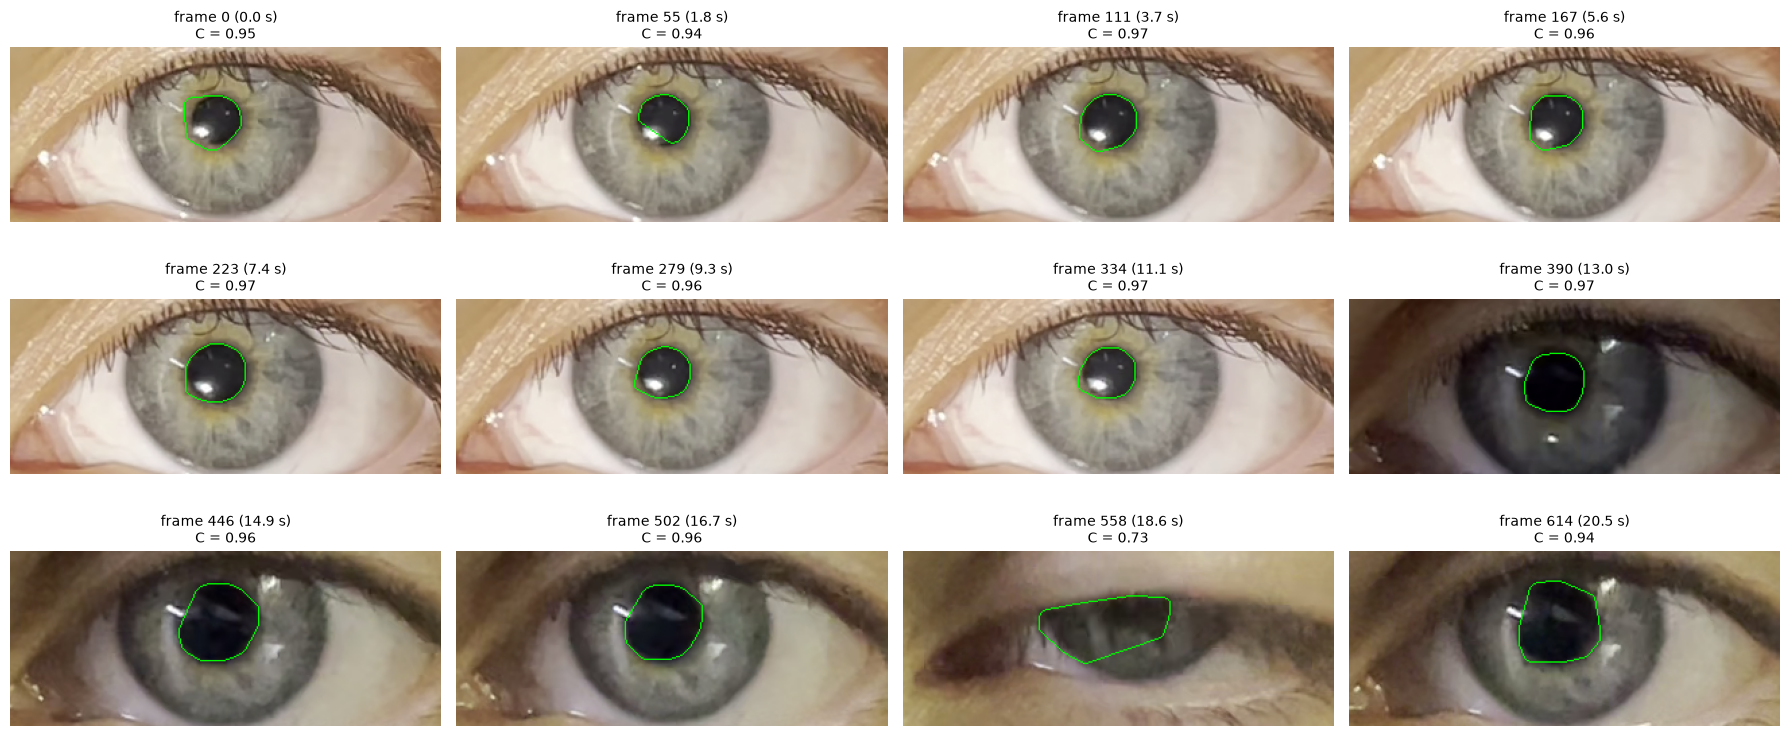

In [143]:
indices = np.linspace(0, n_frames2 - 1, 12).astype(int)

fig, axs = plt.subplots(3, 4, figsize=(18, 8))
for ax, idx in zip(axs.ravel(), indices):
    cap2.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
    ok, frame = cap2.read()
    roi, (cx, cy) = recortar_roi(frame, (int(centros2[idx, 0]), int(centros2[idx, 1])))
    vis = cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)
    contorno = medir_pupila(cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY), cx=cx, cy=cy)
    if contorno is None:
        titulo = f"frame {idx}: sin segmentación"
    else:
        cv2.drawContours(vis, [contorno], -1, (0, 255, 0), 1)
        titulo = f"frame {idx} ({idx / fps2:.1f} s)\nC = {circularidad(contorno):.2f}"
    ax.imshow(vis); ax.set_title(titulo, fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()

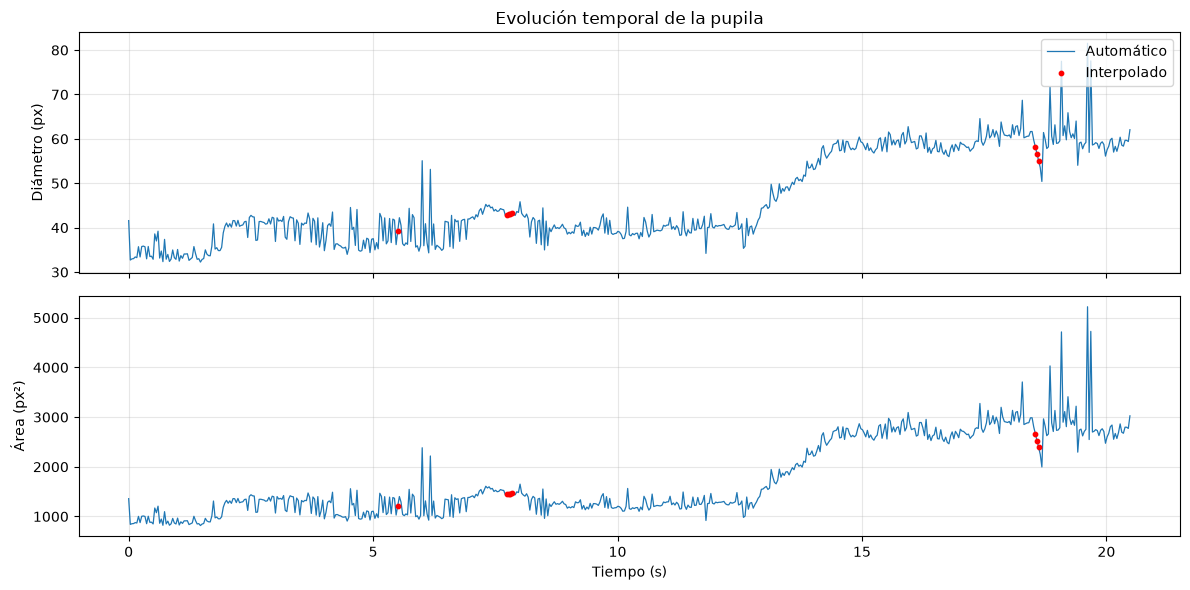

In [144]:
fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, col in [(axs[0], "Diámetro (px)"), (axs[1], "Área (px²)")]:
    ax.plot(df2["t (s)"], df2[col], linewidth=0.9, label="Automático")
    interp = df2[df2["Interpolado"]]
    ax.scatter(interp["t (s)"], interp[col], color="r", s=10, zorder=3, label="Interpolado")
    ax.set_ylabel(col); ax.grid(alpha=0.3)
axs[0].legend(loc="upper right"); axs[1].set_xlabel("Tiempo (s)")
axs[0].set_title("Evolución temporal de la pupila")
plt.tight_layout(); plt.show()

In [145]:
VENTANA_BASE_S = 2.0
FRAC_SUBIDA = 0.9      # fracción de la subida total que marca el final de la redilatación
T_REF = (9, 12)

n_base2 = int(round(VENTANA_BASE_S * fps2))
t2 = df2["t (s)"].values
m_ref = (t2 >= T_REF[0]) & (t2 <= T_REF[1])
i_ref_fin = int(np.where(m_ref)[0][-1])

# Mismo criterio de inicio que la constricción: 10 % por encima del nivel previo durante 5 frames consecutivos
d2 = df2["Diámetro (px)"].values
mu_c = np.nanmedian(d2[m_ref])
i_red = inicio_cambio(d2, i_ref_fin, mu_c, FRAC_INICIO, +1, N_SOSTENIDO)
if i_red is None:
    raise RuntimeError("No se detectó redilatación sostenida después de la ventana de referencia.")
T_REDILATACION = df2.loc[i_red, "t (s)"]
print(f"Nivel previo: {mu_c:.1f} px")
print(f"Inicio de la redilatación: frame {i_red} ({T_REDILATACION:.3f} s)")

# Velocidad media
def redilatacion(serie):
    s = serie.rolling(VENT_MIN, center=True, min_periods=1).median()
    previo = s[m_ref].median()
    final = s.iloc[-n_base2:].median()
    if final <= previo:
        raise RuntimeError("El nivel final no es mayor que el nivel previo: revisar la señal.")
    nivel = previo + FRAC_SUBIDA * (final - previo)
    i_fin = i_red + int(np.argmax(s.iloc[i_red:].values >= nivel))   # primer frame que llega al 90 % de la subida
    return s, previo, final, i_fin

def velocidad_media_redilatacion(serie, unidad):
    s, previo, final, i_fin = redilatacion(serie)
    dur = df2.loc[i_fin, "t (s)"] - T_REDILATACION
    vel = (s.iloc[i_fin] - s.iloc[i_red]) / dur
    return pd.DataFrame({
        f"Nivel previo ({unidad})": [previo],
        f"Nivel final ({unidad})": [final],
        "Duración (s)": [dur],
        f"Velocidad media ({unidad}/s)": [vel],
        "Velocidad relativa (% del nivel final/s)": [100 * vel / final],
    }, index=[""])

print("DIÁMETRO")
display(velocidad_media_redilatacion(df2["Diámetro (px)"], "px").round(2))

Nivel previo: 39.4 px
Inicio de la redilatación: frame 388 (12.943 s)
DIÁMETRO


,Nivel previo (px),Nivel final (px),Duración (s),Velocidad media (px/s),Velocidad relativa (% del nivel final/s)
,39.52,59.06,1.37,9.41,15.94


Se obtiene una velocidad media de redilatación de 9,41 px/s, frente a 7,01 px/s para la constricción. La redilatación resulta entonces más rápida, con una diferencia de 2,40 px/s (~34 % respecto de la constricción), lo cual es contrario a lo esperado, ya que la constricción suele ser más rápida que la redilatación.


Como ambas velocidades provienen de registros distintos, también se las expresó como porcentaje del diámetro de reposo de cada registro (nivel basal en la constricción, nivel final en la redilatación): 12,3 %/s y 15,9 %/s respectivamente. La diferencia persiste, por lo que un cambio de escala de la cámara entre tomas no alcanza para explicarla. Además, los diámetros de reposo de ambos registros son similares (57,2 px y 59,1 px), lo que sugiere escalas comparables.


Sin embargo, cada velocidad proviene de una única medición, de registros distintos, y depende de los criterios elegidos. Por lo tanto, no se puede afirmar que la diferencia sea real. Para corroborlo se deberían haber realizado más registros y repetir la medición, y así estimar la incertidumbre.

A continuación, usamos otro registro de constricción de la pupila para comparar resultados de latencia y amplitud.

FPS: 29.98 | Frames: 768 | Duración: 25.62 s


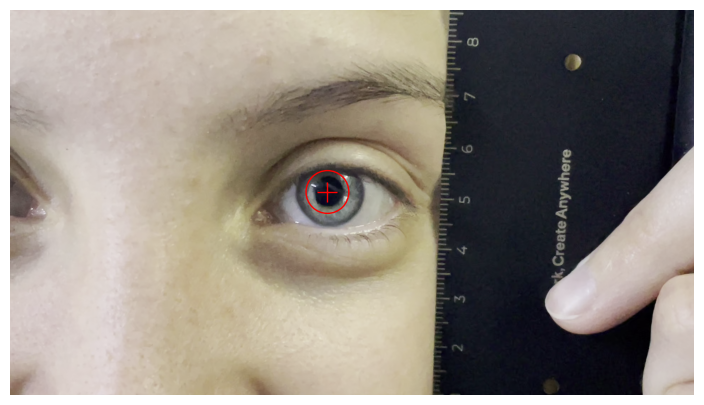

In [146]:
VIDEO_PATH_3 = "../data/raw/Registro A_1.MOV"

cap3 = cv2.VideoCapture(VIDEO_PATH_3)
if not cap3.isOpened():
    raise RuntimeError(f"No se pudo abrir el video: {VIDEO_PATH_3}")
fps3 = cap3.get(cv2.CAP_PROP_FPS)
n_frames3 = int(cap3.get(cv2.CAP_PROP_FRAME_COUNT))
print(f"FPS: {fps3:.2f} | Frames: {n_frames3} | Duración: {n_frames3 / fps3:.2f} s")

CENTRO_INICIAL_3 = (890, 510) 
RADIO_INICIAL_3 = 60              # ventana de búsqueda del primer frame

cap3.set(cv2.CAP_PROP_POS_FRAMES, 0)
ok, frame0 = cap3.read()
plt.figure(figsize=(10, 5))
plt.imshow(cv2.cvtColor(frame0, cv2.COLOR_BGR2RGB))
plt.plot(*CENTRO_INICIAL_3, "r+", ms=15)
plt.gca().add_patch(plt.Circle(CENTRO_INICIAL_3, RADIO_INICIAL_3, fill=False, color="r"))
plt.axis("off"); plt.show()

In [147]:
df3, centros3 = procesar_video(cap3, n_frames3, fps3, CENTRO_INICIAL_3, RADIO_INICIAL_3)

inv = ~df3["Válido"]
rachas = inv.ne(inv.shift()).cumsum()[inv].value_counts()
racha_max = rachas.max() if len(rachas) else 0
print(f"Frames interpolados: {inv.sum()} de {len(df3)} ({100 * inv.mean():.1f} %) | "
      f"racha más larga: {racha_max} frames ({racha_max / fps3:.2f} s)")

Frames interpolados: 22 de 768 (2.9 %) | racha más larga: 3 frames (0.10 s)


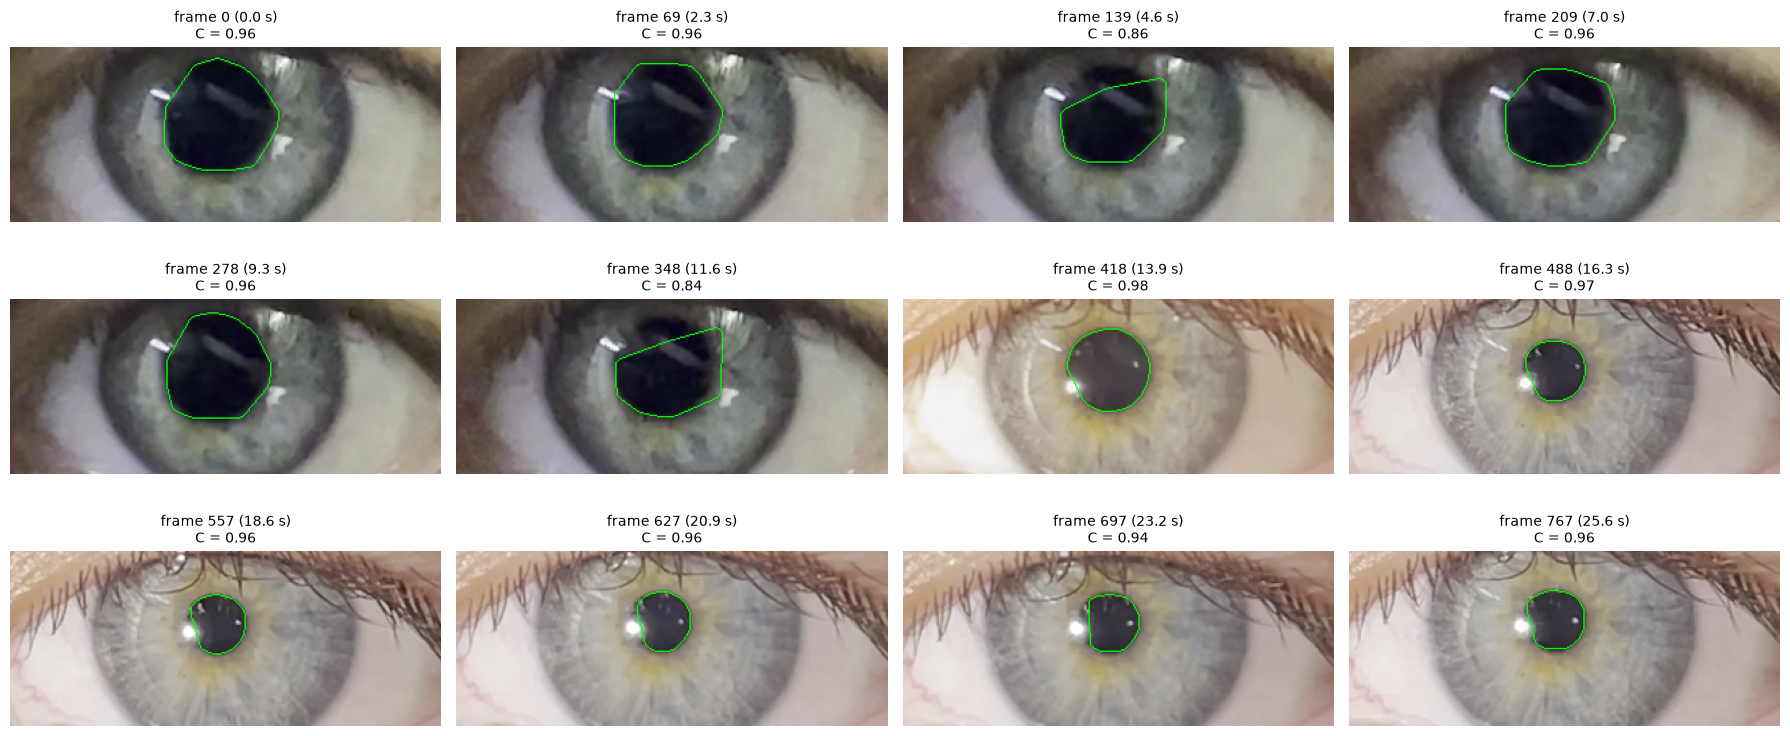

In [148]:
indices = np.linspace(0, n_frames3 - 1, 12).astype(int)

fig, axs = plt.subplots(3, 4, figsize=(18, 8))
for ax, idx in zip(axs.ravel(), indices):
    cap3.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
    ok, frame = cap3.read()
    roi, (cx, cy) = recortar_roi(frame, (int(centros3[idx, 0]), int(centros3[idx, 1])))
    vis = cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)
    contorno = medir_pupila(cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY), cx=cx, cy=cy)
    if contorno is None:
        titulo = f"frame {idx}: sin segmentación"
    else:
        cv2.drawContours(vis, [contorno], -1, (0, 255, 0), 1)
        titulo = f"frame {idx} ({idx / fps3:.1f} s)\nC = {circularidad(contorno):.2f}"
    ax.imshow(vis); ax.set_title(titulo, fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()

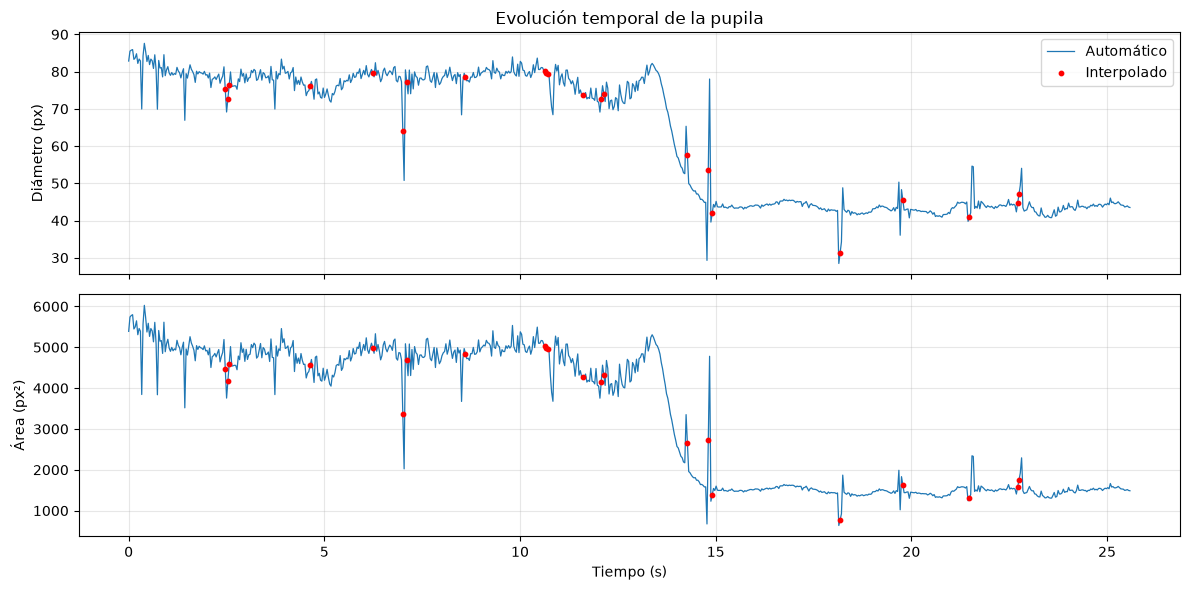

In [149]:
fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, col in [(axs[0], "Diámetro (px)"), (axs[1], "Área (px²)")]:
    ax.plot(df3["t (s)"], df3[col], linewidth=0.9, label="Automático")
    interp = df3[df3["Interpolado"]]
    ax.scatter(interp["t (s)"], interp[col], color="r", s=10, zorder=3, label="Interpolado")
    ax.set_ylabel(col); ax.grid(alpha=0.3)
axs[0].legend(loc="upper right"); axs[1].set_xlabel("Tiempo (s)")
axs[0].set_title("Evolución temporal de la pupila")
plt.tight_layout(); plt.show()

Registro A_1
Estímulo:                  frame 400 (13.343 s)
Inicio de la constricción: frame 412 (13.743 s)
Tiempo de latencia: 400 ms (12 frames)
Línea base: 78.7 px | umbral de caída: 70.8 px
Área basal:  4874 px²
Área mínima: 1339 px² (frame 703, 23.45 s)
Amplitud de respuesta: 3535 px² (72.5 % del área basal)


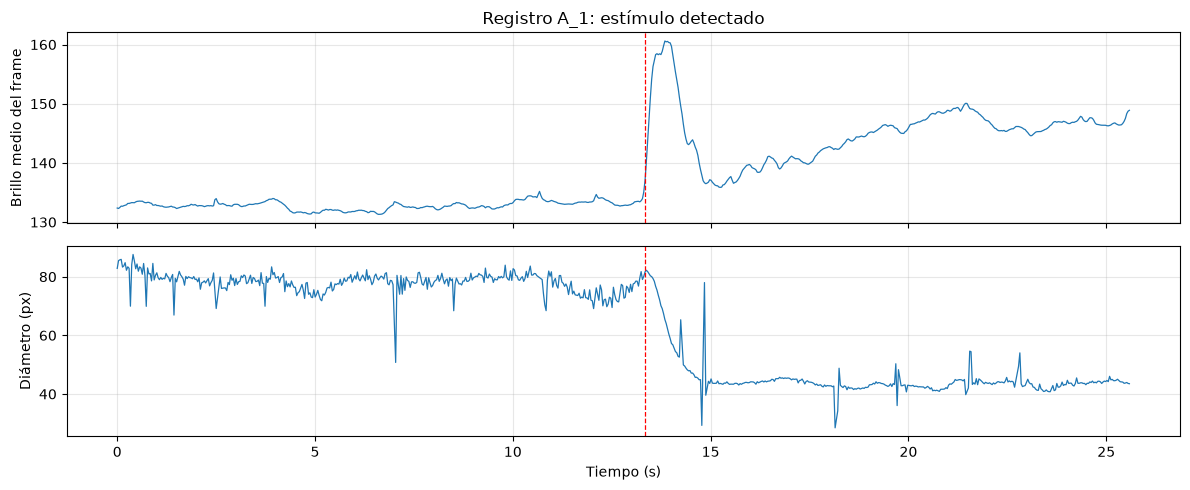

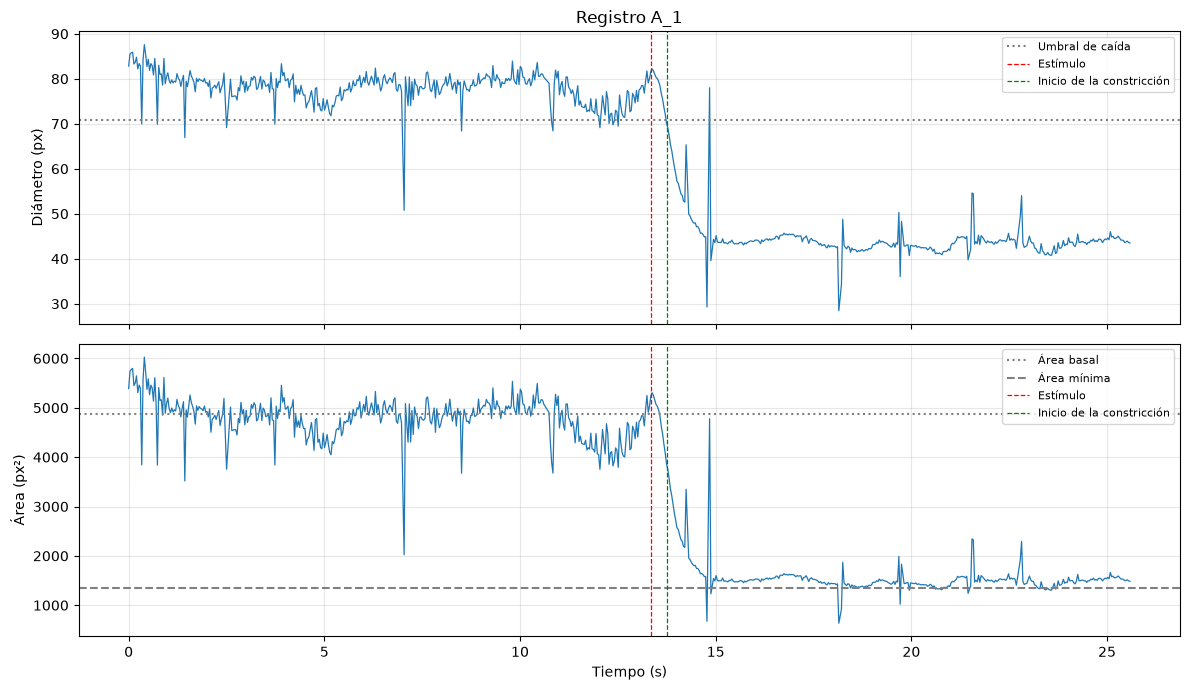

,Registro A_2,Registro A_1
Estímulo (s),21.32,13.34
Latencia (ms),400.29,400.29
Latencia (frames),12.00,12.00
Área basal (px²),2569.50,4874.00
Área mínima (px²),832.50,1339.00
Amplitud (px²),1737.00,3535.00
Amplitud (% del área basal),67.60,72.53


In [150]:
an3 = analizar_registro(df3, cap3, fps3)
mostrar_analisis(df3, an3, "Registro A_1")

claves = ["t_estimulo", "latencia_ms", "latencia_frames", "area_basal", "area_min", "amplitud", "amplitud_pct"]
comparacion = pd.DataFrame({"Registro A_2": an1, "Registro A_1": an3}).loc[claves]
comparacion.index = ["Estímulo (s)", "Latencia (ms)", "Latencia (frames)", "Área basal (px²)",
                     "Área mínima (px²)", "Amplitud (px²)", "Amplitud (% del área basal)"]
display(comparacion.astype(float).round(2))

La latencia es de 400 ms en ambos registros con el criterio del 10 % mayor al rango típico de 200–300 ms. La latencia depende del umbral, ya que el inicio de la constricción es gradual. Las posibles causas del valor alto son: el criterio por umbral detecta la constricción algo después de su inicio real y la resolución del video (~33 ms por frame)

En cuanto a presencia de artefactos, se implementaron los siguientes métodos a lo largo del análisis para poder filtrarlos e interpolarlos:
- Movimientos oculares y de cabeza: la pupila se sigue frame a frame con una ventana de búsqueda centrada en su posición del frame anterior, y la ROI se recorta centrada en ese punto, de modo que el movimiento no desplaza la pupila fuera del análisis.
- Reflejos del flash: los píxeles muy brillantes cercanos a la pupila se detectan, se dilatan y se rellenan con los píxeles de alrededor. Además, se aplica una apertura morfológica y un suavizado gaussiano que eliminan reflejos y pestañas.
- Pestañas y sombras sobre el borde: en la segmentación por Watershed se prueban tres radios de marcador y se elige el contorno con mayor contraste de borde. Luego se aplican una apertura de 11×11, un cierre de 21×21 y la envolvente convexa.

- Para cada frame se calcula la circularidad del contorno. Se consideran inválidos los frames con circularidad < 0,89 y aquellos donde no se pudo segmentar la pupila, que pudo haber sido por parpadeos o errores puntuales de segmentación. Cabe aclarar que este umbral se eligió observando solo el primer video analizado.
- Los valores de área y diámetro de los frames inválidos se reemplazan por interpolación lineal entre los frames válidos vecinos.